# Fixed Telephone Subscriptions, 2000–2024: An Exploratory Data Analysis

**Course:** 04-638 Programming for Data Analytics  |  **Category:** Infrastructure  |  **Group 8**
**Members:** Uwimana Ali Junior, Yvette Izanyibuka, Lion Irumva Kageruka

**Main indicator:** Fixed telephone subscriptions (per 100 people), `IT.MLT.MAIN.P2`
**Supporting indicators:** GDP per capita (current US$), `NY.GDP.PCAP.CD`; Individuals using the Internet (% of population), `IT.NET.USER.ZS`
**Source:** World Bank, World Development Indicators (WDI), last updated 2026-10-08

---
**How this notebook is organised (mirrors the assignment brief)**

| Part | Content |
|---|---|
| 0 | Set up and load the three datasets (first thing, so you can see the data) |
| 1 | Understand the dataset (cursory examination of the raw CSV files) |
| 2 | Analytics objectives and the 12 preliminary questions |
| 3 | Attributes/variables: types, relevance, significance, relationships |
| 4 | Data preparation: load, reshape, filter, merge, coverage check |
| 5 | Exploratory data analysis (5a–5f, including the 8 final questions) |
| 6 | Communicating insights |

**How this notebook follows the class EDA workflow (04-638 *Exploratory Data Analysis* notebook)**

| Class EDA activity | Where it is done here |
|---|---|
| 1. Data collection, loading and assembling | Step 0 (load), 4.1–4.3 (reshape and merge) |
| Examine the data: `head()`, `tail()`, `sample()`, `info()`, `describe()` | 1.3 |
| 2. Data cleaning: keep / remove, split or merge columns, delete irrelevant rows or columns, duplicates, missing values, outliers | 4.0 checklist, 4.1–4.4, 4.6 missing-value policy, 4.7 duplicates, 5d |
| Statistics by class / category (`groupby(...).describe()`) | 5b.2 (by World Bank region) |
| 3a. Univariate: histograms, box plots, skewness and kurtosis | 5b.3–5b.5, 5c.1, 5d |
| 3b. Bivariate: scatter plots, correlation matrix (numerical), heatmap (graphical) | 5c.2–5c.3, Q7, Q9, Q10 |
| 3c. Multivariate: seaborn `pairplot` | 5c.4 |
| 4. Communicate the insights | An **Observation** under every output, 5f answers, Part 6 |

# Step 0: Set up and load the three datasets

This is the first thing we do, so that you can **see the data before any cleaning**. Each code cell starts with a one-line comment saying what it does, and each output is followed by an **Observation** explaining what it shows.

| Cell | What it does |
|---|---|
| 0A | Imports the libraries and sets a few constants |
| 0B | Finds the three CSV files in the notebook's folder |
| 0C | Loads each CSV into a pandas table (DataFrame) |
| 0D | Shows the first rows of each table |

**Put the three `API_...csv` files in the same folder as this notebook** (as you have in VS Code). The notebook also works if the filenames have dots or underscores.

In [1]:
# Libraries, display settings and constants used throughout
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)
pd.options.display.float_format = "{:,.2f}".format

START, END, SNAP = 2000, 2024, 2022
FT, GDP, NET = "fixed_tel", "gdp_pc", "internet"
LABEL = {FT:  "Fixed telephone subscriptions (per 100 people)",
         GDP: "GDP per capita (current US$)",
         NET: "Individuals using the Internet (% of population)"}

In [2]:
# Locate the three World Bank CSV files (same folder as the notebook, or ./data)
FOLDERS  = [".", "data", "/mnt/user-data/uploads"]
PATTERNS = {FT:  "API_IT?MLT?MAIN?P2*.csv",
            GDP: "API_NY?GDP?PCAP?CD*.csv",
            NET: "API_IT?NET?USER?ZS*.csv"}

def find_file(pattern):
    """Return the first file matching `pattern` in any of the FOLDERS, or explain what is wrong."""
    for folder in FOLDERS:
        hits = glob.glob(os.path.join(folder, pattern))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"No file matching {pattern!r} in {FOLDERS}. "
                            f"Put the CSV in the same folder as this notebook. "
                            f"Current working folder: {os.getcwd()}")

PATHS = {key: find_file(pattern) for key, pattern in PATTERNS.items()}
DATA_DIR = os.path.dirname(PATHS[FT]) or "."

for key, path in PATHS.items():
    print(f"{key:10s} -> {os.path.basename(path)}")

fixed_tel  -> API_IT.MLT.MAIN.P2_DS2_en_csv_v2_25577.csv
gdp_pc     -> API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv
internet   -> API_IT.NET.USER.ZS_DS2_en_csv_v2_4964.csv


**Observation.** All three files were found. Each name contains the World Bank indicator code, which confirms we have the main indicator (`IT.MLT.MAIN.P2`) and the two supporting indicators.

In [3]:
# Load each CSV; the first 4 lines of each file are metadata, so they are skipped
raw = {}
for key, path in PATHS.items():
    raw[key] = pd.read_csv(path, skiprows=4)

raw_ft, raw_gdp, raw_net = raw[FT], raw[GDP], raw[NET]

for key in raw:
    print(f"{key:10s} rows = {raw[key].shape[0]}, columns = {raw[key].shape[1]}")

fixed_tel  rows = 266, columns = 71
gdp_pc     rows = 266, columns = 71
internet   rows = 266, columns = 71


**Observation.** The three files have exactly the same shape (266 rows × 71 columns). This means they share one layout (one row per country or group, one column per year), so the same cleaning steps can be applied to all three.

In [4]:
# First 5 rows of each raw table (identifiers and three sample years)
show_cols = ["Country Name", "Country Code", "2000", "2010", "2022"]

print("FIXED TELEPHONE SUBSCRIPTIONS (per 100 people)")
display(raw_ft[show_cols].head())

print("GDP PER CAPITA (current US$)")
display(raw_gdp[show_cols].head())

print("INTERNET USERS (% of population)")
display(raw_net[show_cols].head())

FIXED TELEPHONE SUBSCRIPTIONS (per 100 people)


,Country Name,Country Code,2000,2010,2022
0,Aruba,ABW,42.92,35.00,32.05
1,Africa Eastern and Southern,AFE,1.87,1.81,0.60
2,Afghanistan,AFG,0.14,0.06,0.40
3,Africa Western and Central,AFW,0.66,0.95,0.50
4,Angola,AGO,0.40,1.21,0.26


GDP PER CAPITA (current US$)


,Country Name,Country Code,2000,2010,2022
0,Aruba,ABW,"20,681.02","24,093.14","31,000.57"
1,Africa Eastern and Southern,AFE,706.73,"1,628.77","1,675.90"
2,Afghanistan,AFG,174.93,560.62,357.26
3,Africa Western and Central,AFW,519.64,"1,664.49","2,143.07"
4,Angola,AGO,563.73,"4,101.64","3,598.54"


INTERNET USERS (% of population)


,Country Name,Country Code,2000,2010,2022
0,Aruba,ABW,15.44,62.00,NaN
1,Africa Eastern and Southern,AFE,NaN,5.30,26.80
2,Afghanistan,AFG,NaN,4.00,15.87
3,Africa Western and Central,AFW,NaN,7.30,37.50
4,Angola,AGO,0.11,2.80,35.84


**Observation.** Each table has one row per country or group and one column per year from 1960 to 2025 (a "wide" table). The first rows include groups such as *Africa Eastern and Southern* next to real countries. Some cells are `NaN` (missing): e.g. Internet use for Aruba in 2022 and for *Africa Eastern and Southern* in 2000. The next parts examine and clean these files.

# 1. Understand the Dataset

Now that the files are loaded (Step 0), we **look at them more closely**, including the raw text, the way you would open them in a text editor. This cursory
examination tells us what cleaning will be needed (header rows, empty columns, wide vs long layout, etc.).

In [5]:
# Print the first 6 lines of the raw file as plain text
with open(PATHS[FT], encoding="utf-8-sig") as f:
    for i in range(6):
        print(i, repr(f.readline()[:140]))

0 '"Data Source","World Development Indicators",\n'
1 '\n'
2 '"Last Updated Date","2026-10-08",\n'
3 '\n'
4 '"Country Name","Country Code","Indicator Name","Indicator Code","1960","1961","1962","1963","1964","1965","1966","1967","1968","1969","1970"'
5 '"Aruba","ABW","Fixed telephone subscriptions (per 100 people)","IT.MLT.MAIN.P2","","","","","","","","","","","","","","","","","","","","",'


**Observation.** Lines 0–3 are not data: they hold the source name, the last-updated date (2026-10-08) and blank lines. The real column header is on line 4. Missing years are stored as empty strings (`""`), which pandas reads as `NaN`.

In [6]:
# Show why skiprows=4 is needed, then inspect the columns
try:
    naive = pd.read_csv(PATHS[FT])
    print("Naive read -> shape:", naive.shape)
except pd.errors.ParserError as e:
    print("Naive read FAILS:", str(e)[:90])
print()

print("With skiprows=4 -> shape:", raw_ft.shape)
print("First 5 columns :", list(raw_ft.columns[:5]))
print("Last 3 columns  :", list(raw_ft.columns[-3:]))
print("Trailing 'Unnamed' column is entirely empty:", raw_ft.filter(like="Unnamed").isna().all().all())
raw_ft.iloc[:5, [0, 1, 3, 44, 54, 64, 65]]

Naive read FAILS: Error tokenizing data. C error: Expected 3 fields in line 5, saw 71


With skiprows=4 -> shape: (266, 71)
First 5 columns : ['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960']
Last 3 columns  : ['2024', '2025', 'Unnamed: 70']
Trailing 'Unnamed' column is entirely empty: True


,Country Name,Country Code,Indicator Code,2000,2010,2020,2021
0,Aruba,ABW,IT.MLT.MAIN.P2,42.92,35.00,32.59,32.54
1,Africa Eastern and Southern,AFE,IT.MLT.MAIN.P2,1.87,1.81,0.70,0.60
2,Afghanistan,AFG,IT.MLT.MAIN.P2,0.14,0.06,0.37,0.36
3,Africa Western and Central,AFW,IT.MLT.MAIN.P2,0.66,0.95,0.50,0.50
4,Angola,AGO,IT.MLT.MAIN.P2,0.40,1.21,0.36,0.35


**Observation.** Reading the file without `skiprows` fails because the first line has only 3 fields while data lines have 71. With `skiprows=4` we get the correct 266 × 71 table. The last column, `Unnamed: 70`, is completely empty; it comes from the trailing comma on every line and will be dropped.

### 1.3 Examine the data

In class we examined a new dataset with `head()`, `tail()`, `sample()`, `info()` and `describe()` before doing anything else. We do the same here on the raw fixed-telephone table. Showing only the identifier columns and a few years keeps the output readable.

In [7]:
# head(): first 10 rows
look_cols = ["Country Name", "Country Code", "2000", "2008", "2015", "2022", "2024"]
raw_ft[look_cols].head(10)

,Country Name,Country Code,2000,2008,2015,2022,2024
0,Aruba,ABW,42.92,39.32,33.59,32.05,NaN
1,Africa Eastern and Southern,AFE,1.87,1.85,1.30,0.60,0.50
2,Afghanistan,AFG,0.14,NaN,0.33,0.40,NaN
3,Africa Western and Central,AFW,0.66,0.97,0.70,0.50,0.40
4,Angola,AGO,0.40,0.53,1.01,0.26,0.21
5,Albania,ALB,4.82,11.48,7.82,6.27,5.92
6,Andorra,AND,52.09,44.76,53.83,63.82,64.95
7,Arab World,ARB,6.90,10.08,7.40,9.48,NaN
8,United Arab Emirates,ARE,29.20,25.32,26.04,22.32,20.80
9,Argentina,ARG,21.21,24.10,23.17,15.51,14.05


**Observation.** The first 10 rows mix real countries (Aruba, Afghanistan, Angola) with **groups** such as *Africa Eastern and Southern* (`AFE`) and *Arab World* (`ARB`), because rows are sorted by country code. Values already show the main story: most economies listed have fewer lines in 2022 than in 2008 (e.g. Argentina 24.1 → 15.5), while a few rose (Andorra 44.8 → 63.8). Several 2024 cells are `NaN`.

In [8]:
# tail(): last 10 rows
raw_ft[look_cols].tail(10)

,Country Name,Country Code,2000,2008,2015,2022,2024
256,Virgin Islands (U.S.),VIR,62.89,69.37,75.81,87.66,NaN
257,Viet Nam,VNM,3.30,17.34,7.89,2.40,2.62
258,Vanuatu,VUT,3.56,4.58,1.80,1.10,0.93
259,World,WLD,15.91,18.50,14.10,10.90,10.20
260,Samoa,WSM,4.69,NaN,5.68,2.12,NaN
261,Kosovo,XKX,NaN,5.90,NaN,6.53,NaN
262,"Yemen, Rep.",YEM,1.77,3.83,3.67,1.90,NaN
263,South Africa,ZAF,10.52,9.54,7.28,2.10,1.58
264,Zambia,ZMB,0.83,0.70,0.71,0.48,0.35
265,Zimbabwe,ZWE,2.10,2.69,2.32,1.81,1.79


**Observation.** The last 10 rows include another aggregate, *World* (`WLD`), whose value fell from 18.5 in 2008 to 10.9 in 2022. Some countries have gaps in the middle of the series (Kosovo has no 2000 or 2015 value; Samoa none for 2008), so missing values are not only a recent-year problem.

In [9]:
# sample(): 15 random rows (fixed seed so the result is reproducible)
raw_ft[look_cols].sample(15, random_state=8)

,Country Name,Country Code,2000,2008,2015,2022,2024
260,Samoa,WSM,4.69,NaN,5.68,2.12,NaN
55,Germany,DEU,61.40,62.01,55.25,45.88,45.42
69,Eritrea,ERI,1.36,1.44,2.13,2.00,NaN
56,Djibouti,DJI,1.30,1.67,2.24,2.46,NaN
25,Belarus,BLR,27.54,39.02,47.86,46.11,45.76
30,Barbados,BRB,47.25,49.50,53.60,42.97,NaN
84,Gibraltar,GIB,84.96,78.91,NaN,45.61,NaN
172,New Caledonia,NCL,22.86,24.82,27.45,16.22,NaN
131,Liberia,LBR,0.23,0.05,0.19,0.12,NaN
258,Vanuatu,VUT,3.56,4.58,1.80,1.10,0.93


**Observation.** A random sample confirms the same features: an aggregate appears again (*Sub-Saharan Africa (excluding high income)*), values range from near zero (Liberia 0.12, Guinea-Bissau 0.00) to high (Germany 45.9, Belarus 46.1), and 2024 is missing for most of the sampled rows.

In [10]:
# info(): size, column types and memory
raw_ft.info(verbose=False)
print()
print(raw_ft.dtypes.value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Columns: 71 entries, Country Name to Unnamed: 70
dtypes: float64(67), str(4)
memory usage: 167.3 KB

float64    67
str         4
Name: count, dtype: int64


**Observation.** The table has 266 rows and 71 columns: 4 text columns (country name/code, indicator name/code) and 67 numeric (`float64`) columns, i.e. the 66 years 1960–2025 plus the empty `Unnamed` column. The year columns are already numeric, so no type conversion is needed.

In [11]:
# describe(): statistics for selected years (raw file, aggregates still included)
raw_ft[["2000", "2008", "2015", "2022", "2024"]].describe()

,2000,2008,2015,2022,2024
count,254.00,255.00,257.00,258.00,178.00
mean,20.26,20.74,17.71,14.90,13.43
std,21.92,19.57,17.79,16.48,14.82
min,0.02,0.05,0.00,0.00,0.00
25%,2.44,3.78,2.24,1.91,1.61
50%,10.52,16.47,14.15,10.25,10.08
75%,31.43,30.97,25.45,22.20,19.75
max,92.34,109.94,133.54,109.55,95.48


**Observation.** Even before cleaning, the median rises from 10.5 (2000) to 16.5 (2008) and then falls to 10.3 (2022). The count drops from 258 rows in 2022 to 178 in 2024, so 2024 is incomplete. The maxima above 100 (up to 133.5) are possible because the indicator counts lines, not people. These numbers still include aggregates, so they are only a first look.

### What the cursory examination tells us

* Each file is a **World Bank "wide" table**: one row per country/aggregate and **one column per year** (1960–2025).
* The first **4 lines are metadata** (source, update date, blank lines), so we need `skiprows=4`.
* Every line ends with a trailing comma, which creates an **empty `Unnamed` column** that must be dropped.
* The 266 rows are **not all countries**: they include regional/income aggregates (World, High income, Sub-Saharan Africa, ...) and the code `INX` (Not classified). These must be removed so we do not double-count.
* Many cells are blank, which are **missing values** (not zeros). Coverage differs by indicator and year.
* The files do **not** contain a region column, so we add one (see Part 4).

# 2. Analytics Objectives and Preliminary Questions

**Objective.** Describe how fixed telephone subscriptions changed from 2000 to 2024, how they differ across countries and regions, and how they relate to GDP per capita and Internet use, with **Rwanda** as a comparison case.

### Supporting indicators and expected relationships

| Indicator | Justification (relationship we expect to explore) |
|---|---|
| **GDP per capita (current US$)** | Building and maintaining fixed networks requires economic resources, so we expect subscription levels to differ across economies with different income, in a single year and over time. |
| **Individuals using the Internet (% of population)** | Internet use shows how widely newer communication channels have spread. We examine whether higher or faster-growing Internet use goes with different fixed-telephone patterns, **without assuming one technology replaces the other**. |

### The 12 preliminary questions (★ = the eight answered in the final EDA)

| No. | Question | Indicators | Period |
|---|---|---|---|
| 1 ★ | How did the median fixed telephone subscriptions per 100 people change from 2000 to 2024, and did it peak at any point? | Fixed tel. | Each year |
| 2 | How did the distributions differ between 2000 and 2022; did the gap between high- and low-subscription economies narrow or widen? | Fixed tel. | 2000 vs 2022 |
| 3 ★ | Which economies had the largest increases and declines between 2000 and 2022? | Fixed tel. | Change 2000–2022 |
| 4 ★ | When did each economy record its highest rate (2000–2022), and how far below that peak was its 2022 value? | Fixed tel. | 2000–2022 |
| 5 ★ | How did subscriptions differ across the seven World Bank regions in 2000 and 2022; did differences change? | Fixed tel., region | 2000, 2022 |
| 6 | Which economies show unusually large one-year rises/falls, and do these occur near reporting gaps or zeros? | Fixed tel. | 2000–2024 |
| 7 ★ | In 2022, how are subscriptions associated with GDP per capita, and does the pattern look different on a log GDP scale? | Fixed tel., GDP | 2022 |
| 8 | How did subscriptions differ across GDP-per-capita quartile groups in 2000 and 2022? | Fixed tel., GDP | 2000 vs 2022 |
| 9 ★ | In 2022, how are subscriptions associated with Internet use? | Fixed tel., Internet | 2022 |
| 10 ★ | Between 2000 and 2022, did economies with larger Internet increases show rises, falls, or no clear pattern in subscriptions? | Fixed tel., Internet | Change 2000–2022 |
| 11 ★ | How did Rwanda's three indicators from 2000 to 2024 compare with the median of the other Sub-Saharan African economies? | All three | Each year |
| 12 | Among economies with similar GDP per capita in 2022, do those with higher Internet use have higher or lower subscriptions? | All three | 2022 |

Four of the eight final questions (Q7, Q9, Q10, Q11) combine fixed telephone data with a supporting indicator, which satisfies the "at least three" requirement. Questions 2, 6, 8 and 12 are not in the final eight, but we touch on Q2 and Q6 in Part 5 because they help explain the data.

# 3. Understand the Attributes: Types, Relevance, Significance and Relationships

In [12]:
# Data dictionary: type, scale and role of each attribute
dictionary = pd.DataFrame([
    ["Country Name", "text (object)", "Nominal / identifier", "Label for plots and tables. Spellings can differ across sources, so it is NOT used as a merge key."],
    ["Country Code", "text (object)", "Nominal / identifier", "ISO3-style code (e.g. RWA). Used as the unique merge key across the three files."],
    ["Indicator Name / Code", "text (object)", "Constant per file", "Documents which indicator the file holds; dropped after loading."],
    ["Year columns 1960-2025", "float64 (wide)", "Ratio / time index", "One column per year. Reshaped into a single `year` column (integer); analysis window is 2000-2024."],
    ["IT.MLT.MAIN.P2 (fixed_tel)", "float64", "Ratio, continuous", "MAIN variable. Active fixed lines per 100 people; can exceed 100 (lines, not people)."],
    ["NY.GDP.PCAP.CD (gdp_pc)", "float64", "Ratio, continuous, right-skewed", "SUPPORTING. Economic capacity; current US$ so it mixes real growth with inflation and exchange-rate moves."],
    ["IT.NET.USER.ZS (internet)", "float64", "Ratio, bounded 0-100", "SUPPORTING. Share of people using the Internet; measures usage of newer communication, not lines."],
    ["region (added)", "category", "Nominal", "World Bank region (7 groups); enables regional comparison (Q5, Q11)."],
], columns=["Attribute", "Python type", "Measurement scale", "Relevance / significance"])
dictionary

,Attribute,Python type,Measurement scale,Relevance / significance
0,Country Name,text (object),Nominal / identifier,Label for plots and tables. Spellings can diff...
1,Country Code,text (object),Nominal / identifier,ISO3-style code (e.g. RWA). Used as the unique...
2,Indicator Name / Code,text (object),Constant per file,Documents which indicator the file holds; drop...
3,Year columns 1960-2025,float64 (wide),Ratio / time index,One column per year. Reshaped into a single `y...
4,IT.MLT.MAIN.P2 (fixed_tel),float64,"Ratio, continuous",MAIN variable. Active fixed lines per 100 peop...
5,NY.GDP.PCAP.CD (gdp_pc),float64,"Ratio, continuous, right-skewed",SUPPORTING. Economic capacity; current US$ so ...
6,IT.NET.USER.ZS (internet),float64,"Ratio, bounded 0-100",SUPPORTING. Share of people using the Internet...
7,region (added),category,Nominal,World Bank region (7 groups); enables regional...


**Expected relationships (hypotheses to test, not conclusions).**
* `fixed_tel` and `gdp_pc`: positive association likely at a point in time, but probably **non-linear** because GDP per capita spans several orders of magnitude (hence a log scale in Q7).
* `fixed_tel` and `internet`: could be positive in a snapshot (both reflect infrastructure) yet **negative over time** (people moving to mobile/Internet-based services). The cross-section and the change-over-time questions (Q9 vs Q10) test exactly this contrast.
* `internet` and `gdp_pc`: expected to be strongly positive; this matters for Q12 because it means the two supporting indicators overlap.

# 4. Prepare and Clean the Data

The raw files were already loaded in Step 0. Steps here: (1) drop the empty column, (2) reshape to long format, (3) remove aggregates and `INX`, (4) add the World Bank **region**, (5) merge the three indicators on `(country code, year)`, (6) keep 2000–2024, (7) run the coverage check and compare it with our proposal.

### 4.0 Data-cleaning checklist (the activities listed in the class EDA notebook)

| Class cleaning activity | What we did and why |
|---|---|
| **What do you keep** | All 217 individual economies, the years 2000–2024, and the three indicator values. |
| **What do you remove** | The 48 regional/income aggregate codes (World, High income, Sub-Saharan Africa, ...) and `INX` (Not classified), because they would double-count economies; years before 2000 and the year 2025 (outside the assignment window; 2025 has no fixed-telephone values at all). |
| **Split or merge columns** | The 66 year columns are *melted* into one `year` column (wide → long). The three files are *merged* on `Country Code` + `year`. A `region` column is added. |
| **Delete irrelevant rows or columns** | `Indicator Name` and `Indicator Code` (constant in each file) and the empty `Unnamed: 70` column are dropped. |
| **Delete duplicate rows or columns** | Checked in 4.7: no duplicate economies or economy-years. |
| **Drop or fill missing values** | Not filled. Missing values stay as `NaN` and each analysis uses the economies that have the values it needs (policy in 4.6, details in 5d). |
| **Detect (and remove) outliers** | Detected and reported in 5d with the 1.5×IQR rule, but **not removed**: the assignment asks us to report them, and they are real values (mostly small high-income economies).

In [13]:
# Reshape each file from wide (one column per year) to long (one row per country-year)
def load_wdi(key):
    """Take the raw table for one indicator and return a long table: country, code, year, value."""
    df = raw[key].copy()
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    years = [c for c in df.columns if c.isdigit()]
    long = df.melt(id_vars=["Country Name", "Country Code"],
                   value_vars=years,
                   var_name="year", value_name=key)
    long["year"] = long["year"].astype(int)
    return long

long_tables = {k: load_wdi(k) for k in (FT, GDP, NET)}
for k, t in long_tables.items():
    print(f"{k:10s} long shape: {t.shape}")
long_tables[FT].head()

fixed_tel  long shape: (17556, 4)
gdp_pc     long shape: (17556, 4)
internet   long shape: (17556, 4)


,Country Name,Country Code,year,fixed_tel
0,Aruba,ABW,1960,NaN
1,Africa Eastern and Southern,AFE,1960,0.84
2,Afghanistan,AFG,1960,0.09
3,Africa Western and Central,AFW,1960,0.06
4,Angola,AGO,1960,0.12


**Observation.** Each indicator is now a long table of 17,556 rows (266 countries/groups × 66 years) with four columns: name, code, year and value. Year is now a single integer column, which makes filtering by period and merging much easier.

In [14]:
# Aggregate codes to remove, and the World Bank region of each economy
AGGREGATES = set("""AFE AFW ARB CEB CSS EAP EAR EAS ECA ECS EMU EUU FCV HIC HPC IBD IBT IDA IDB IDX LAC LCN LDC LIC LMC LMY
LTE MEA MIC MNA NAC OED OSS PRE PSS PST SAS SSA SSF SST TEA TEC TLA TMN TSA TSS UMC WLD""".split())
UNCLASSIFIED = {"INX"}

REGION_CODES = {
 "East Asia & Pacific": "ASM AUS BRN CHN FJI FSM GUM HKG IDN JPN KHM KIR KOR LAO MAC MHL MMR MNG MNP MYS NCL NRU NZL PHL PLW PNG PRK PYF SGP SLB THA TLS TON TUV VNM VUT WSM",
 "Europe & Central Asia": "ALB AND ARM AUT AZE BEL BGR BIH BLR CHE CHI CYP CZE DEU DNK ESP EST FIN FRA FRO GBR GEO GIB GRC GRL HRV HUN IMN IRL ISL ITA KAZ KGZ LIE LTU LUX LVA MCO MDA MKD MLT MNE NLD NOR POL PRT ROU RUS SMR SRB SVK SVN SWE TJK TKM TUR UKR UZB XKX",
 "Latin America & Caribbean": "ABW ARG ATG BHS BLZ BOL BRA BRB CHL COL CRI CUB CUW CYM DMA DOM ECU GRD GTM GUY HND HTI JAM KNA LCA MAF MEX NIC PAN PER PRI PRY SLV SUR SXM TCA TTO URY VCT VEN VGB VIR",
 "Middle East, North Africa, Afghanistan & Pakistan": "AFG ARE BHR DJI DZA EGY IRN IRQ ISR JOR KWT LBN LBY MAR OMN PAK PSE QAT SAU SYR TUN YEM",
 "North America": "BMU CAN USA",
 "South Asia": "BGD BTN IND LKA MDV NPL",
 "Sub-Saharan Africa": "AGO BDI BEN BFA BWA CAF CIV CMR COD COG COM CPV ERI ETH GAB GHA GIN GMB GNB GNQ KEN LBR LSO MDG MLI MOZ MRT MUS MWI NAM NER NGA RWA SDN SEN SLE SOM SSD STP SWZ SYC TCD TGO TZA UGA ZAF ZMB ZWE",
}
REGION_MAP = {c: r for r, codes in REGION_CODES.items() for c in codes.split()}

meta_files = glob.glob(os.path.join(DATA_DIR, "Metadata_Country_*.csv"))
if meta_files:
    meta = pd.read_csv(meta_files[0]).dropna(subset=["Region"])
    REGION_MAP = dict(zip(meta["Country Code"], meta["Region"]))
    print("Using official country metadata:", os.path.basename(meta_files[0]))
else:
    print("Using the built-in region mapping (no Metadata_Country file found).")

Using the built-in region mapping (no Metadata_Country file found).


**Observation.** The built-in region list was used because no `Metadata_Country` file was found. The list covers every economy kept after removing the aggregates (checked in the next cell).

In [15]:
# Merge the three indicators on country code + year, drop aggregates, keep 2000-2024, add region
panel = (long_tables[FT]
         .merge(long_tables[GDP][["Country Code", "year", GDP]], on=["Country Code", "year"], how="outer")
         .merge(long_tables[NET][["Country Code", "year", NET]], on=["Country Code", "year"], how="outer")
         .rename(columns={"Country Name": "country", "Country Code": "iso3"}))

panel = panel[~panel["iso3"].isin(AGGREGATES | UNCLASSIFIED)]
panel = panel[panel["year"].between(START, END)].copy()
panel["region"] = panel["iso3"].map(REGION_MAP)

n_econ = panel["iso3"].nunique()
print("Economies kept:", n_econ, "| country-years:", len(panel), "| expected 217 x 25 =", 217 * 25)
print("Economies without a region:", panel.loc[panel["region"].isna(), "iso3"].unique())
print("Regions:", panel["region"].nunique())
panel.groupby("region")["iso3"].nunique().rename("economies").to_frame()

Economies kept: 217 | country-years: 5425 | expected 217 x 25 = 5425
Economies without a region: <ArrowStringArray>
[]
Length: 0, dtype: str
Regions: 7


,economies
region,
East Asia & Pacific,37
Europe & Central Asia,59
Latin America & Caribbean,42
"Middle East, North Africa, Afghanistan & Pakistan",22
North America,3
South Asia,6
Sub-Saharan Africa,48


**Observation.** After merging and filtering we have exactly **217 economies × 25 years = 5,425 rows**, every economy has a region, and there are 7 regions. Europe & Central Asia (59) and Sub-Saharan Africa (48) contain the most economies; North America has only 3 (Bermuda, Canada, United States) and South Asia 6, so medians for those two regions rest on very few economies.

In [16]:
# Look-up tables and wide (economy x year) tables used in the EDA
names  = panel.drop_duplicates("iso3").set_index("iso3")["country"]
region = panel.drop_duplicates("iso3").set_index("iso3")["region"]

wide = {k: panel.pivot(index="iso3", columns="year", values=k) for k in (FT, GDP, NET)}
ft, gdp, net = wide[FT], wide[GDP], wide[NET]

panel["log10_gdp"] = np.log10(panel[GDP])
panel.head()

,country,iso3,year,fixed_tel,gdp_pc,internet,region,log10_gdp
40,Aruba,ABW,2000,42.92,"20,681.02",15.44,Latin America & Caribbean,4.32
41,Aruba,ABW,2001,41.12,"20,740.13",17.10,Latin America & Caribbean,4.32
42,Aruba,ABW,2002,40.64,"21,307.25",18.80,Latin America & Caribbean,4.33
43,Aruba,ABW,2003,40.50,"21,949.49",20.80,Latin America & Caribbean,4.34
44,Aruba,ABW,2004,40.77,"23,700.63",23.00,Latin America & Caribbean,4.37


**Observation.** The cleaned panel has one row per economy-year with the three indicators side by side (e.g. Aruba 2000: 42.9 lines per 100 people, US$20,681, 15.4% Internet use) plus region and log10 GDP.

### 4.5 Coverage check (reproduces the table in the proposal)

In [17]:
# Coverage of each indicator, 2000-2024
possible = n_econ * (END - START + 1)

def coverage_row(name, mask_wide):
    """mask_wide is a True/False table (economy x year): True = a value exists."""
    return {"Indicator": name,
            "Economies with any data": int(mask_wide.any(axis=1).sum()),
            "Complete, all 25 yrs": int(mask_wide.all(axis=1).sum()),
            "Available country-years": int(mask_wide.values.sum()),
            "Coverage %": round(100 * mask_wide.values.sum() / possible, 1),
            2000: int(mask_wide[2000].sum()), 2022: int(mask_wide[2022].sum()), 2024: int(mask_wide[2024].sum())}

avail = {k: wide[k].notna() for k in (FT, GDP, NET)}
avail_all = avail[FT] & avail[GDP] & avail[NET]
coverage = pd.DataFrame([coverage_row("Fixed telephone", avail[FT]),
                         coverage_row("GDP per capita", avail[GDP]),
                         coverage_row("Internet use", avail[NET]),
                         coverage_row("All three matched", avail_all)]).set_index("Indicator")
coverage

,Economies with any data,"Complete, all 25 yrs",Available country-years,Coverage %,2000,2022,2024
Indicator,,,,,,,
Fixed telephone,213,136,5052,93.10,206,212,146
GDP per capita,214,196,5242,96.60,204,209,200
Internet use,210,155,4890,90.10,196,182,182
All three matched,206,114,4693,86.50,192,180,137


**Observation.** This should match the proposal (213 / 136 / 5,052 / 93.1% for fixed telephone; 214 / 196 / 5,242 / 96.6% for GDP; 210 / 155 / 4,890 / 90.1% for Internet; 206 / 114 / 4,693 / 86.5% for all three). The sharp fall in fixed-telephone coverage between 2022 and 2024 is why we use **2022 as the snapshot year** and compare **2000 with 2022**.

### 4.6 Missing-value and zero policy
* Missing values are **never replaced with zero**. They stay as `NaN`, and each analysis uses only the economies that have the values it needs (the number of economies is always reported).
* Fixed-telephone values that are **exactly 0** are kept as reported but inspected in Part 5d.
* No imputation is applied to the main analysis; for time-series charts, gaps are shown as gaps.

### 4.7 Duplicate check

In [18]:
# Check for duplicate rows, codes and columns
for key, t in raw.items():
    print(f"{key:10s} duplicate full rows: {t.duplicated().sum()} | duplicate country codes: {t['Country Code'].duplicated().sum()} "
          f"| duplicate column names: {t.columns.duplicated().sum()}")
print("Duplicate (economy, year) pairs in the merged panel:", panel.duplicated(subset=["iso3", "year"]).sum())
print("Same set of country codes in all three files:",
      set(raw_ft['Country Code']) == set(raw_gdp['Country Code']) == set(raw_net['Country Code']))

fixed_tel  duplicate full rows: 0 | duplicate country codes: 0 | duplicate column names: 0
gdp_pc     duplicate full rows: 0 | duplicate country codes: 0 | duplicate column names: 0
internet   duplicate full rows: 0 | duplicate country codes: 0 | duplicate column names: 0
Duplicate (economy, year) pairs in the merged panel: 0
Same set of country codes in all three files: True


**Observation.** There are no duplicate rows, codes or column names, and each economy-year appears once in the merged panel, so nothing has to be deleted. All three files contain the same 266 codes, so the merge does not lose or add any economy.

**Result.** There are no duplicate rows, codes or column names, and every economy-year appears exactly once in the merged panel, so nothing needs to be deleted. All three files contain the same 266 codes, so the merge does not lose or add any economy.

# 5. Exploratory Data Analysis

## 5a. Understanding the data: attributes, types, size and significant fields

In [19]:
# Size and structure of the cleaned panel
print("Rows x columns:", panel.shape)
print("Memory (MB):", round(panel.memory_usage(deep=True).sum() / 1e6, 2))
print("Economies:", panel["iso3"].nunique(), "| Years:", panel["year"].min(), "-", panel["year"].max())
print()
panel.info()

Rows x columns: (5425, 8)
Memory (MB): 0.59
Economies: 217 | Years: 2000 - 2024

<class 'pandas.DataFrame'>
Index: 5425 entries, 40 to 17554
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    5425 non-null   str    
 1   iso3       5425 non-null   str    
 2   year       5425 non-null   int64  
 3   fixed_tel  5052 non-null   float64
 4   gdp_pc     5242 non-null   float64
 5   internet   4890 non-null   float64
 6   region     5425 non-null   str    
 7   log10_gdp  5242 non-null   float64
dtypes: float64(4), int64(1), str(3)
memory usage: 573.7 KB


**Observation.** The analysis table has 5,425 rows and 8 columns. The non-null counts show the missing data directly: fixed telephone has 5,052 values (373 missing), GDP 5,242 (183 missing) and Internet use 4,890 (535 missing). Identifiers, year and region are complete.

In [20]:
# Summary statistics, all years pooled
panel[[FT, GDP, NET]].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed_tel,"5,052.00",19.51,19.94,0.00,2.83,13.80,30.74,140.09
gdp_pc,"5,242.00","16,314.53","25,475.38",109.59,"1,576.38","5,464.72","21,289.68","288,001.57"
internet,"4,890.00",39.96,32.22,0.00,8.00,34.53,69.85,100.00


**Observation.** Pooled over all years, fixed telephone has a median of 13.8 and a maximum of 140.1 lines per 100 people; GDP per capita ranges from US$110 to US$288,002 (median US$5,465); Internet use covers the full 0–100% range (median 34.5%). Pooling mixes early and late years, so the year-by-year statistics in 5b are more informative. The **significant fields** are `fixed_tel` (the main variable), `gdp_pc` and `internet` (context), `year` (trends) and `region` (group comparisons); `iso3` is the key that links the three sources.

## 5b. Basic statistics and the distribution of the numeric data

### 5b.1 Summary statistics for 2000 and 2022

In [21]:
# Summary statistics for 2000 and 2022
rows = []
for y in (2000, 2022):
    for k in (FT, GDP, NET):
        s = wide[k][y].dropna()
        rows.append({"Year": y, "Indicator": LABEL[k][:32], "n": len(s),
                     "Mean": s.mean(), "Median": s.median(), "Std": s.std(),
                     "Min": s.min(), "Q1": s.quantile(.25), "Q3": s.quantile(.75), "Max": s.max(),
                     "Skewness": s.skew()})
pd.DataFrame(rows).set_index(["Year", "Indicator"])

n      Mean   Median       Std    Min       Q1        Q3        Max  Skewness
Year Indicator                                                                                                        
2000 Fixed telephone subscriptions (p  206     21.48    11.63     22.76   0.02     2.47     35.84      92.34      1.08
     GDP per capita (current US$)      204  8,206.01 1,985.55 12,969.23 122.27   635.43 11,554.33  81,789.01      2.64
     Individuals using the Internet (  196      8.73     2.32     13.32   0.00     0.38      9.52      52.00      1.84
2022 Fixed telephone subscriptions (p  212     15.76    10.88     17.37   0.00     2.07     24.41     109.55      1.72
     GDP per capita (current US$)      209 21,200.87 7,655.59 31,131.45 301.83 2,899.16 28,360.30 226,052.06      3.06
     Individuals using the Internet (  182     70.24    78.78     25.27   7.14    57.00     89.50     100.00     -0.94

**Observation.** For all three indicators the **mean is far from the median**, which signals skewed data. Fixed telephone: mean 21.5 vs median 11.6 in 2000, and 15.8 vs 10.9 in 2022; both the median and the maximum economy changed, but the typical economy fell only slightly. GDP per capita: the median almost quadrupled (US$1,986 → US$7,656, in current dollars). Internet use: the median jumped from 2.3% to 78.8%, and the skewness changed sign (1.84 → −0.94).

### 5b.2 Statistics by category: World Bank region, 2022

In class we compared statistics *by class* with `groupby('class')[variable].describe()`. Our categorical variable is the World Bank **region**, so we do the same for each indicator in the 2022 snapshot year.

In [22]:
# Statistics by region (like groupby('class').describe() in class)
snap = panel[panel["year"] == SNAP]
print(f"Fixed telephone subscriptions per 100 people by region, {SNAP}")
snap.groupby("region")[FT].describe()

Fixed telephone subscriptions per 100 people by region, 2022


,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
East Asia & Pacific,37.00,16.09,16.54,0.00,2.40,12.59,24.46,49.45
Europe & Central Asia,57.00,25.99,19.41,2.25,11.59,23.92,38.24,109.55
Latin America & Caribbean,39.00,19.58,17.51,0.01,9.59,14.59,22.32,87.66
"Middle East, North Africa, Afghanistan & Pakistan",22.00,13.00,9.89,0.40,5.84,12.35,17.12,39.26
North America,3.00,31.59,6.32,26.63,28.03,29.42,34.06,38.70
South Asia,6.00,3.53,3.93,0.17,2.07,2.53,2.66,11.31
Sub-Saharan Africa,48.00,2.07,5.71,0.00,0.11,0.40,1.71,36.21


**Observation.** The regional medians in 2022 range from **0.40** lines per 100 people in Sub-Saharan Africa and 2.5 in South Asia to 23.9 in Europe & Central Asia and 29.4 in North America. In Sub-Saharan Africa the mean (2.07) is five times the median because of one economy, Mauritius (36.2), so medians describe regions better than means. Spread within regions is wide: Europe & Central Asia runs from 2.3 (Tajikistan) to 109.6 (Monaco).

In [23]:
print(f"GDP per capita (current US$) by region, {SNAP}")
snap.groupby("region")[GDP].describe()

GDP per capita (current US$) by region, 2022


,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
East Asia & Pacific,36.00,"18,408.64","21,094.41","1,158.05","3,697.63","6,682.84","33,842.87","91,227.70"
Europe & Central Asia,58.00,"40,212.68","43,833.10","1,052.18","10,028.16","26,614.40","53,782.63","226,052.06"
Latin America & Caribbean,39.00,"16,875.56","16,609.49","1,748.41","6,571.03","11,405.79","20,879.90","92,937.88"
"Middle East, North Africa, Afghanistan & Pakistan",21.00,"18,022.93","23,900.27",357.26,"3,654.36","4,754.41","30,470.52","88,701.46"
North America,3.00,"84,824.93","32,280.45","56,496.93","67,252.81","78,008.69","98,988.93","119,969.17"
South Asia,6.00,"4,203.73","3,803.36","1,385.91","2,389.11","3,029.56","3,619.15","11,786.02"
Sub-Saharan Africa,46.00,"2,600.23","3,173.10",301.83,865.68,"1,341.51","2,599.73","16,682.70"


**Observation.** GDP per capita follows a similar regional order: Sub-Saharan Africa has the lowest median (US$1,342) and North America the highest (US$78,009). Europe & Central Asia has the largest spread (std US$43,833), from US$1,052 to US$226,052 (Monaco). Counts differ slightly from the fixed-telephone table (e.g. 46 vs 48 in Sub-Saharan Africa) because of missing values.

In [24]:
print(f"Internet use (% of population) by region, {SNAP}")
snap.groupby("region")[NET].describe()

Internet use (% of population) by region, 2022


,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
East Asia & Pacific,26.00,76.09,21.18,18.26,65.74,81.82,92.18,98.97
Europe & Central Asia,52.00,88.18,8.35,48.91,83.89,89.11,94.02,99.00
Latin America & Caribbean,33.00,74.26,10.84,47.77,68.42,74.75,81.51,92.32
"Middle East, North Africa, Afghanistan & Pakistan",18.00,83.51,20.03,15.87,79.20,89.27,97.34,100.00
North America,2.00,93.36,0.90,92.73,93.05,93.36,93.68,94.00
South Asia,6.00,60.59,20.38,41.62,46.16,52.10,76.91,88.36
Sub-Saharan Africa,45.00,38.15,20.69,7.14,21.51,35.20,56.83,84.83


**Observation.** Internet use does **not** line up neatly with fixed lines. The Middle East/North Africa/Afghanistan/Pakistan group has a median of 89.3%, as high as Europe & Central Asia (89.1%), even though its median fixed-telephone rate (12.4) is about half of Europe's. Sub-Saharan Africa is lowest (35.2%). Coverage is thinner here: only 26 of 37 East Asia & Pacific economies and 2 of 3 North American economies report Internet use for 2022.

### 5b.3 Distributions in 2000 vs 2022 (all three indicators side by side)

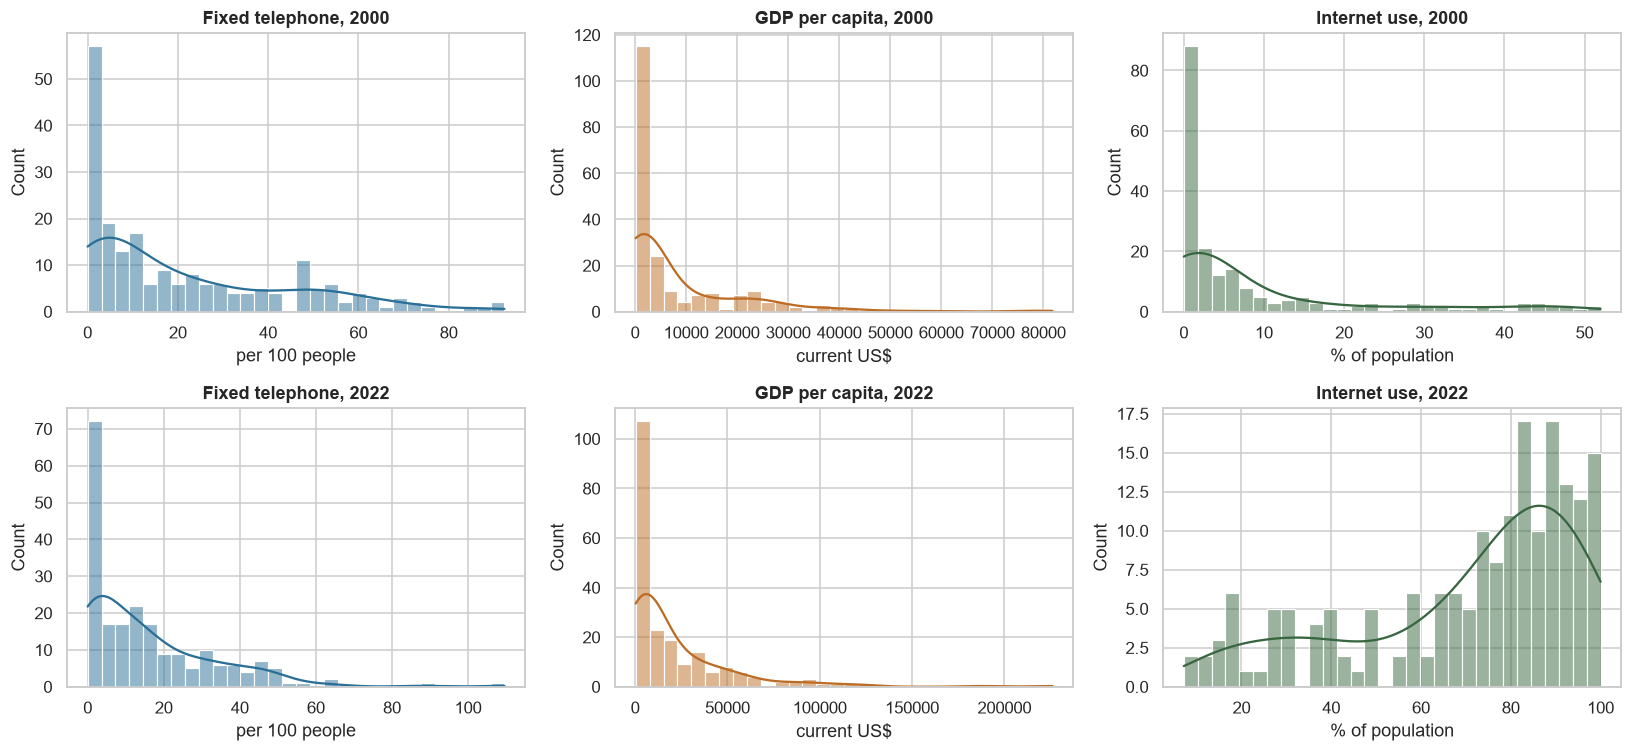

In [25]:
# Histograms of the three indicators: 2000 (top) vs 2022 (bottom)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, y in enumerate((2000, 2022)):
    sns.histplot(ft[y].dropna(), bins=30, kde=True, ax=axes[i, 0], color="#2a6f97")
    axes[i, 0].set_title(f"Fixed telephone, {y}"); axes[i, 0].set_xlabel("per 100 people")
    sns.histplot(gdp[y].dropna(), bins=30, kde=True, ax=axes[i, 1], color="#bc6c25")
    axes[i, 1].set_title(f"GDP per capita, {y}"); axes[i, 1].set_xlabel("current US$")
    sns.histplot(net[y].dropna(), bins=30, kde=True, ax=axes[i, 2], color="#386641")
    axes[i, 2].set_title(f"Internet use, {y}"); axes[i, 2].set_xlabel("% of population")
plt.tight_layout(); plt.show()

**Observation.** **Fixed telephone** is concentrated near zero in both years with a long right tail; in 2000 there is a second bump around 45–60 lines (mostly high-income economies) that has largely disappeared by 2022. **GDP per capita** is piled up at the left in both years, with a few very rich economies stretching the axis. **Internet use** changed completely: in 2000 almost all economies were below 10%, while in 2022 most are between 70% and 100%.

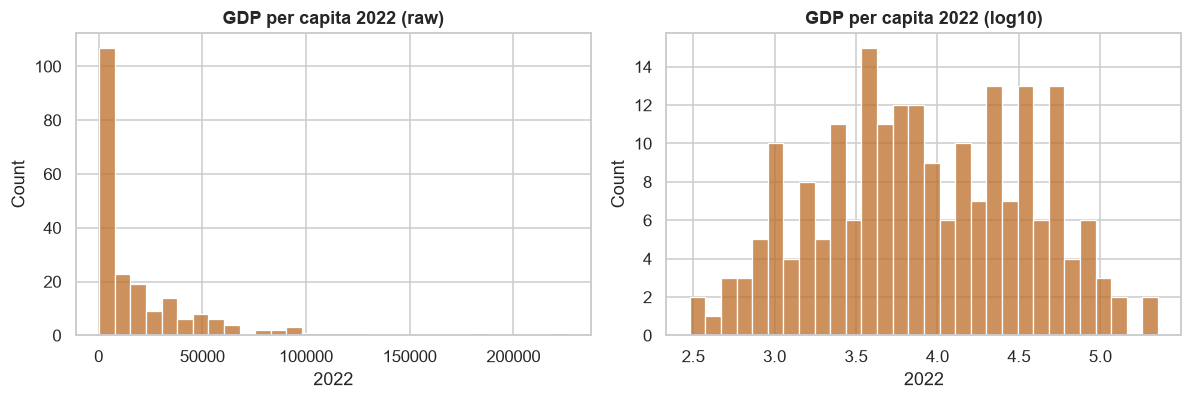

Skewness of GDP raw vs log10: 3.06 vs -0.05


In [26]:
# GDP per capita on the raw scale vs log10 scale
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(gdp[SNAP].dropna(), bins=30, ax=ax[0], color="#bc6c25"); ax[0].set_title(f"GDP per capita {SNAP} (raw)")
sns.histplot(np.log10(gdp[SNAP].dropna()), bins=30, ax=ax[1], color="#bc6c25"); ax[1].set_title(f"GDP per capita {SNAP} (log10)")
plt.tight_layout(); plt.show()
print("Skewness of GDP raw vs log10:", round(gdp[SNAP].skew(), 2), "vs", round(np.log10(gdp[SNAP].dropna()).skew(), 2))

**Observation.** On the raw scale almost all economies sit in the first one or two bars, so the shape cannot be seen. On the log10 scale GDP per capita is spread fairly evenly between about 10^2.5 (US$300) and 10^5 (US$100,000), and the skewness falls from 3.06 to −0.05. This is why GDP is used on a log scale when compared with other variables.

### 5b.4 Univariate analysis: one histogram per variable (class style)

Following the class notebook, we draw a simple matplotlib histogram for each variable on its own (2022 snapshot), with the variable on the x-axis and the frequency (number of economies) on the y-axis.

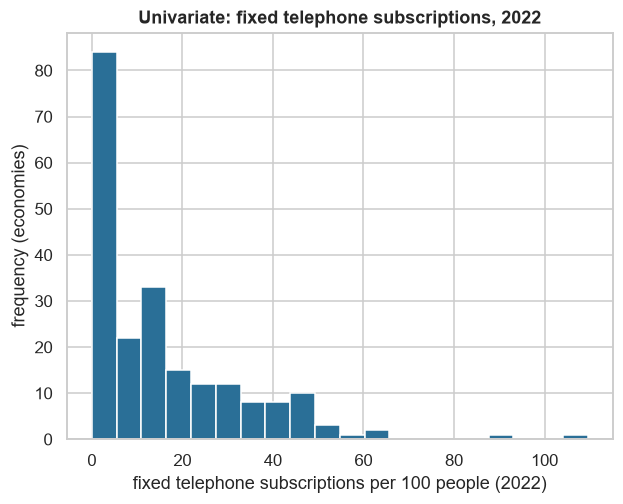

In [27]:
plt.hist(ft[SNAP].dropna(), bins=20, color="#2a6f97", edgecolor="white")
plt.xlabel("fixed telephone subscriptions per 100 people (2022)")
plt.ylabel("frequency (economies)")
plt.title("Univariate: fixed telephone subscriptions, 2022")
plt.show()

**Observation.** About 84 of 212 economies fall in the first bar (below about 5.5 lines per 100 people), and 42 economies have fewer than 1 line per 100 people. Frequencies then fall steadily, with only a couple of economies beyond 80 (U.S. Virgin Islands 87.7, Monaco 109.6).

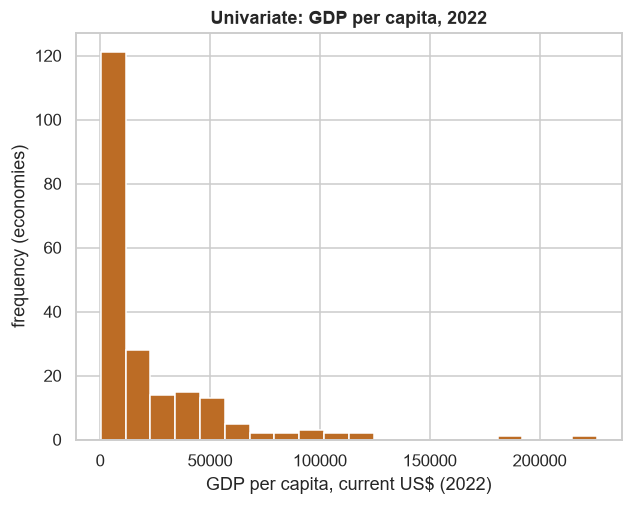

In [28]:
plt.hist(gdp[SNAP].dropna(), bins=20, color="#bc6c25", edgecolor="white")
plt.xlabel("GDP per capita, current US$ (2022)")
plt.ylabel("frequency (economies)")
plt.title("Univariate: GDP per capita, 2022")
plt.show()

**Observation.** About 120 of 209 economies fall in the first bar (GDP per capita below about US$11,000), while a handful exceed US$100,000. The single bars far to the right are Liechtenstein and Monaco. This extreme right skew is what the log transform corrects.

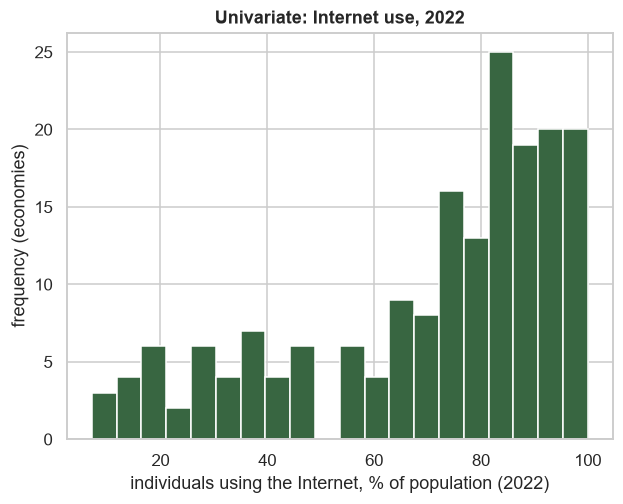

In [29]:
plt.hist(net[SNAP].dropna(), bins=20, color="#386641", edgecolor="white")
plt.xlabel("individuals using the Internet, % of population (2022)")
plt.ylabel("frequency (economies)")
plt.title("Univariate: Internet use, 2022")
plt.show()

**Observation.** The bars rise towards the right: the most common range is 80–100% Internet use, while a smaller group of economies (mostly in Sub-Saharan Africa) remains below 50%. The lowest value is Burundi at 7.1%.

### 5b.5 Skewness and kurtosis

The class notebook lists **skewness** and **kurtosis** as univariate measures.
* **Skewness** > 0: long tail to the right (a few very high values); < 0: long tail to the left; about 0: roughly symmetric.
* **Kurtosis** (pandas reports *excess* kurtosis, so a normal distribution = 0): > 0 means heavier tails / more extreme values than a normal curve; < 0 means flatter, with fewer extremes.

In [30]:
# Skewness and excess kurtosis (a normal distribution has 0 for both)
rows = []
for y in (2000, SNAP):
    for k in (FT, GDP, NET):
        s = wide[k][y].dropna()
        rows.append({"Year": y, "Indicator": k, "n": len(s), "Mean": s.mean(), "Median": s.median(),
                     "Skewness": s.skew(), "Excess kurtosis": s.kurt()})
s_ = np.log10(gdp[SNAP].dropna())
rows.append({"Year": SNAP, "Indicator": "log10_gdp", "n": len(s_), "Mean": s_.mean(), "Median": s_.median(),
             "Skewness": s_.skew(), "Excess kurtosis": s_.kurt()})
shape_tbl = pd.DataFrame(rows).set_index(["Year", "Indicator"])
shape_tbl

n      Mean   Median  Skewness  Excess kurtosis
Year Indicator                                                   
2000 fixed_tel  206     21.48    11.63      1.08             0.26
     gdp_pc     204  8,206.01 1,985.55      2.64             8.99
     internet   196      8.73     2.32      1.84             2.32
2022 fixed_tel  212     15.76    10.88      1.72             4.44
     gdp_pc     209 21,200.87 7,655.59      3.06            13.05
     internet   182     70.24    78.78     -0.94            -0.28
     log10_gdp  209      3.92     3.88     -0.05            -0.83

**Observation.** Fixed telephone is right-skewed in both years (1.08 → 1.72), and its excess kurtosis rose from **0.26 to 4.44**: by 2022 most economies are bunched at low values while a few stay far out in the tail (Monaco, U.S. Virgin Islands). GDP per capita is the most skewed and heavy-tailed variable (3.06 and 13.05 in 2022), but after log10 it is nearly symmetric (−0.05) and slightly flatter than normal (−0.83). Internet use moved from right-skewed (1.84) to left-skewed (−0.94) as most economies approached the top of the 0–100% scale.

## 5c. Visualisations to understand and communicate the data

### 5c.1 Box plots over time

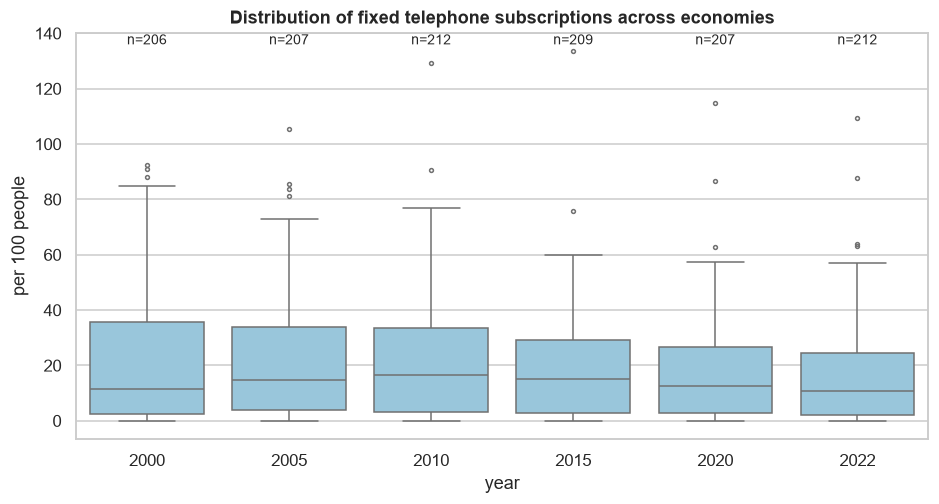

In [31]:
# Box plots of fixed telephone subscriptions for selected years
years_box = [2000, 2005, 2010, 2015, 2020, 2022]
box_df = panel[panel["year"].isin(years_box)].dropna(subset=[FT])
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=box_df, x="year", y=FT, color="#8ecae6", ax=ax, fliersize=2.5)
ax.set_title("Distribution of fixed telephone subscriptions across economies"); ax.set_ylabel("per 100 people")
for i, y in enumerate(years_box):
    ax.text(i, ax.get_ylim()[1] * 0.97, f"n={int(ft[y].count())}", ha="center", fontsize=9)
plt.show()

**Observation.** The median line rises from 2000 to 2010 and then falls back by 2022. The top of the box (75th percentile) falls steadily, from about 36 in 2000 to about 24 in 2022, while the bottom of the box stays near 2: high-subscription economies lost lines while low-subscription economies stayed low. The points above 120 in 2010 and 2015 are Monaco (129.4 and 133.5).

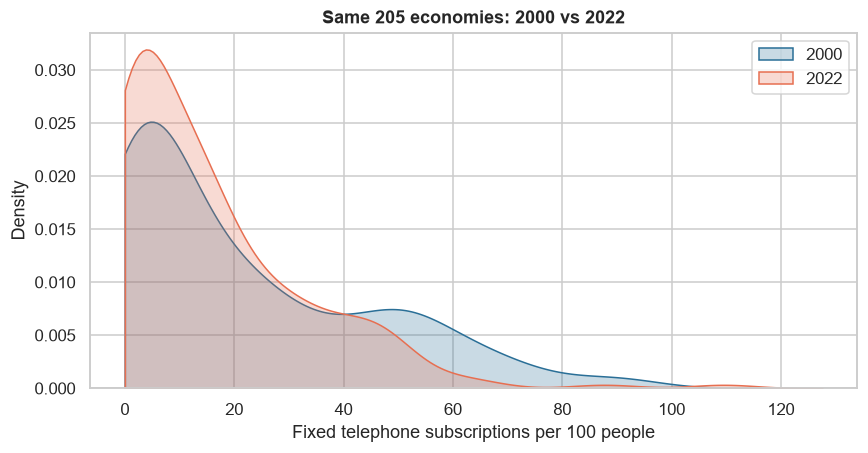

,25%,50%,75%,IQR,P90 - P10
2000,2.37,11.51,36.02,33.65,54.74
2022,2.10,10.80,23.83,21.73,41.36


In [32]:
# Same economies in 2000 and 2022: density curves and measures of spread
both = pd.concat([ft[2000].rename("2000"), ft[2022].rename("2022")], axis=1).dropna()
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.kdeplot(both["2000"], fill=True, label="2000", ax=ax, color="#2a6f97", clip=(0, None))
sns.kdeplot(both["2022"], fill=True, label="2022", ax=ax, color="#e76f51", clip=(0, None))
ax.set_xlabel("Fixed telephone subscriptions per 100 people"); ax.set_title(f"Same {len(both)} economies: 2000 vs 2022")
ax.legend(); plt.show()

q = both.describe().loc[["25%", "50%", "75%"]].T
q["IQR"] = q["75%"] - q["25%"]
q["P90 - P10"] = [both[c].quantile(.9) - both[c].quantile(.1) for c in both]
q

**Observation.** For the same 205 economies, the 2022 curve is taller near zero and the 2000 bump at 40–70 lines has mostly gone. The interquartile range shrank from 33.7 to 21.7 and the 10th–90th percentile gap from 54.7 to 41.4. This answers preliminary **Q2**: the gap between high- and low-subscription economies **narrowed**, but because the top quartile fell (36.0 → 23.8), not because the bottom quartile rose (2.4 → 2.1).

### 5c.2 Bivariate analysis: scatter plots of each pair of variables (class style)

As in class, we plot each pair of numeric variables against each other with `plt.scatter`, one economy per dot, for 2022. GDP per capita is shown on a log scale because of its strong right skew (5b.5).

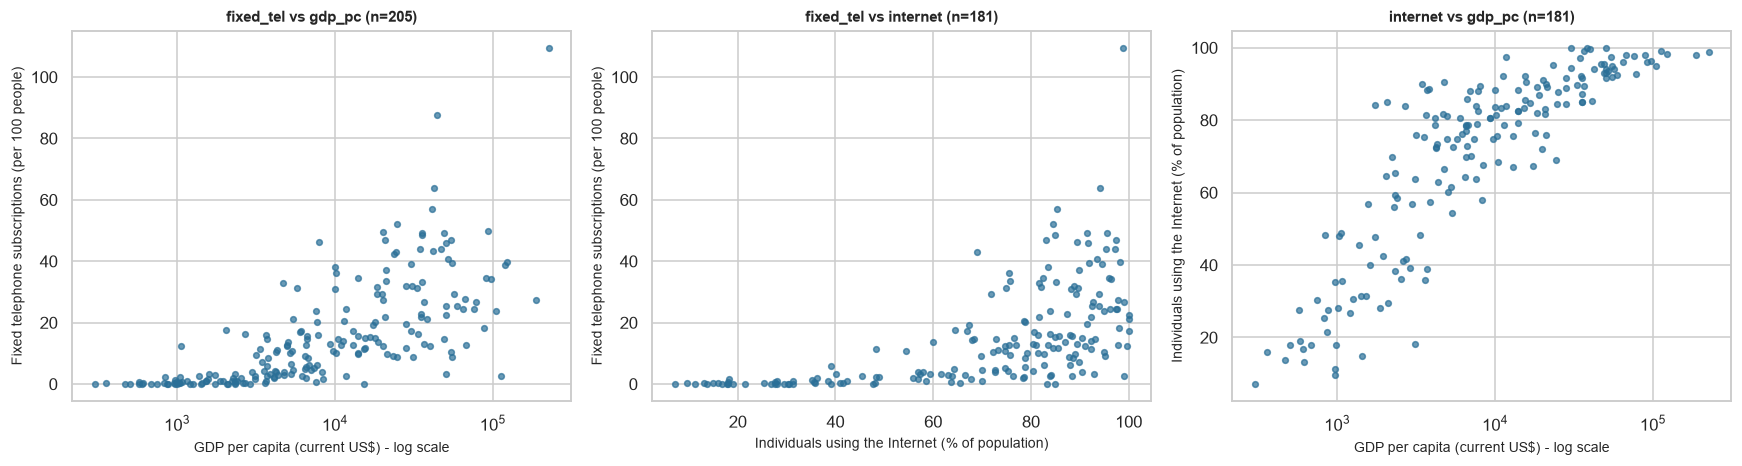

In [33]:
# Scatter plot of each pair of indicators, 2022 (GDP on a log scale)
s22 = pd.DataFrame({FT: ft[SNAP], GDP: gdp[SNAP], NET: net[SNAP]})
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
pairs = [(GDP, FT), (NET, FT), (GDP, NET)]
for ax, (x, y) in zip(axes, pairs):
    d = s22[[x, y]].dropna()
    ax.scatter(d[x], d[y], s=14, alpha=.7, color="#2a6f97")
    if x == GDP: ax.set_xscale("log")
    ax.set_xlabel(LABEL[x] + (" - log scale" if x == GDP else ""), fontsize=9)
    ax.set_ylabel(LABEL[y], fontsize=9)
    ax.set_title(f"{y} vs {x} (n={len(d)})", fontsize=10)
plt.tight_layout(); plt.show()

**Observation.** Fixed telephone rises with both log GDP and Internet use, but in a **fan shape**: at low income or low Internet use nearly every economy has close to zero lines, while at high income or high Internet use values range from about 3 to over 60. The third panel (Internet use vs log GDP) is the tightest, almost straight-line cloud of the three.

### 5c.3 Bivariate analysis: correlation matrix, numerically then graphically

The class notebook first prints `data.corr()` (numerically) and then draws it with `sns.heatmap` (graphically). We show the default **Pearson** matrix (straight-line association) and the **Spearman** matrix (rank-based, robust to skew and outliers), using 2022 data.

In [34]:
# Pearson correlation matrix, 2022
s22["log10_gdp"] = np.log10(s22[GDP])
corr_pearson = s22[[FT, GDP, "log10_gdp", NET]].corr()
corr_pearson

,fixed_tel,gdp_pc,log10_gdp,internet
fixed_tel,1.00,0.61,0.69,0.58
gdp_pc,0.61,1.00,0.78,0.52
log10_gdp,0.69,0.78,1.00,0.86
internet,0.58,0.52,0.86,1.00


**Observation.** Pearson correlations are all positive. Fixed telephone vs GDP is 0.61 on the raw scale and 0.69 with log GDP, so the log scale captures the relationship better. Fixed telephone vs Internet use is 0.58. The strongest pair is Internet use vs log GDP (0.86), much stronger than with raw GDP (0.52).

In [35]:
# Spearman (rank) correlation matrix, 2022
corr_spearman = s22[[FT, GDP, "log10_gdp", NET]].corr(method="spearman")
corr_spearman

,fixed_tel,gdp_pc,log10_gdp,internet
fixed_tel,1.00,0.80,0.80,0.74
gdp_pc,0.80,1.00,1.00,0.88
log10_gdp,0.80,1.00,1.00,0.88
internet,0.74,0.88,0.88,1.00


**Observation.** Spearman correlations are higher than Pearson: 0.80 for fixed telephone vs GDP and 0.74 vs Internet use. GDP and log GDP give identical Spearman values (1.00 with each other) because taking logs does not change the ranking of economies. The two supporting indicators are strongly related to each other (0.88), so in one year it is hard to separate their links with fixed lines.

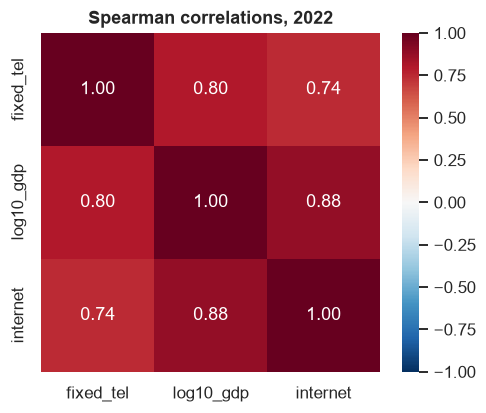

In [36]:
# Heatmap of the Spearman correlation matrix
cols = [FT, "log10_gdp", NET]
plt.figure(figsize=(5.2, 4))
sns.heatmap(corr_spearman.loc[cols, cols], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title(f"Spearman correlations, {SNAP}"); plt.show()

**Observation.** The heatmap shows the same Spearman matrix in colour: every cell is dark red (positive), and the darkest off-diagonal cell is log GDP vs Internet use (0.88). There are no negative correlations in the 2022 cross-section.

### 5c.4 Multivariate analysis: pair plot coloured by region

In class we used `sns.pairplot(data, hue='class')` to see every pair of variables at once, with the diagonal showing each variable's distribution. Here the categories are the World Bank regions and the variables are the three indicators for 2022 (GDP as log10).

Economies in the pair plot: 180


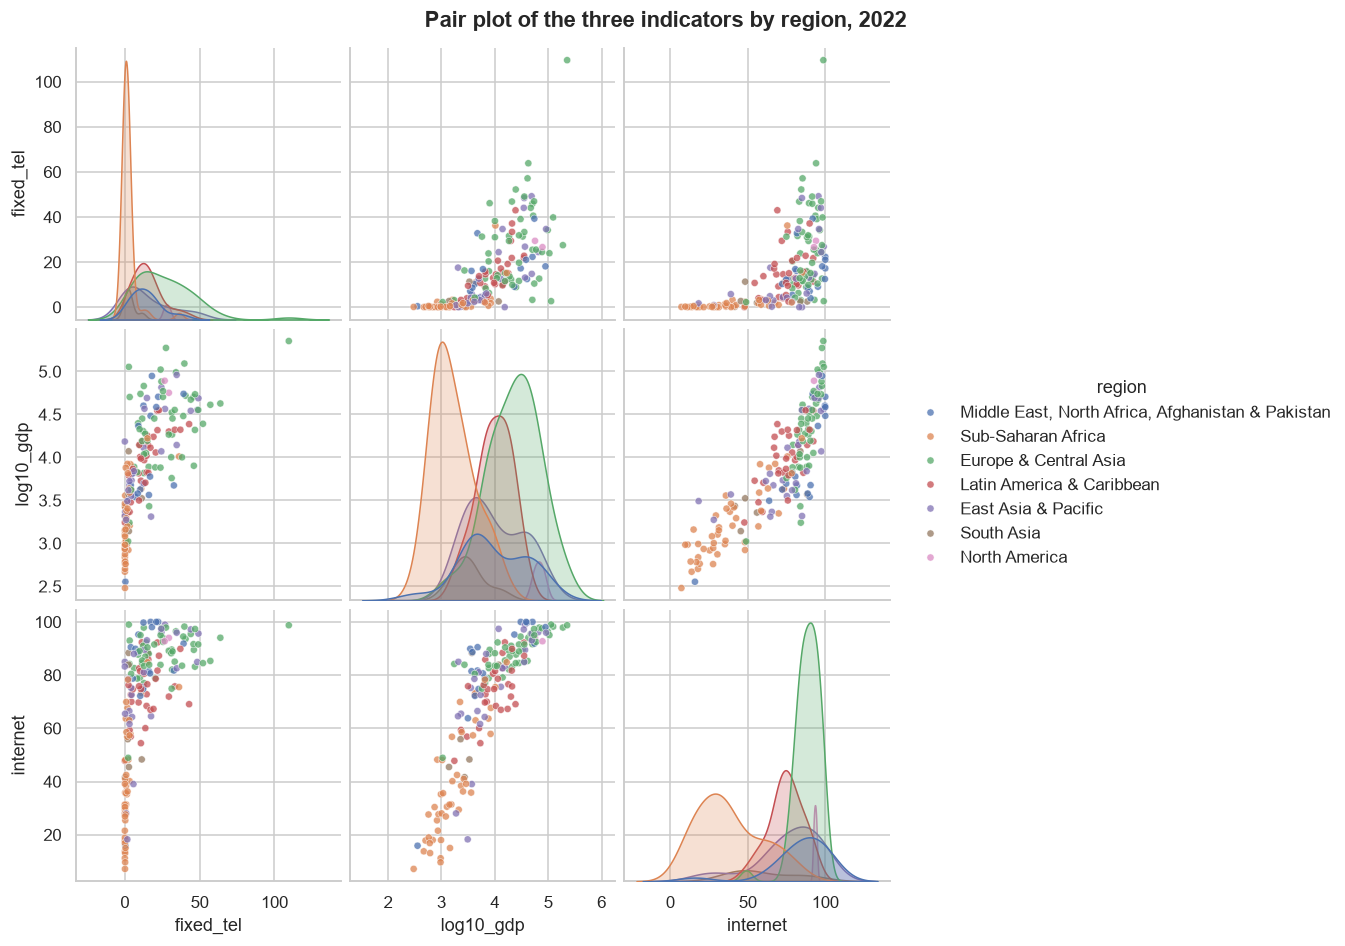

In [37]:
# Pair plot of the three indicators, coloured by region
pp = snap[["region", FT, "log10_gdp", NET]].dropna()
print("Economies in the pair plot:", len(pp))
g = sns.pairplot(data=pp, hue="region", vars=[FT, "log10_gdp", NET],
                 plot_kws={"s": 22, "alpha": .75}, diag_kind="kde", height=2.8)
g.fig.suptitle(f"Pair plot of the three indicators by region, {SNAP}", y=1.02, fontweight="bold")
plt.show()

**Observation.** In 180 economies with all three values, the regions separate clearly. Sub-Saharan Africa (orange) clusters at low GDP, low-to-middle Internet use and near-zero fixed lines; Europe & Central Asia (green) sits at high GDP and high Internet use with the widest range of fixed lines; Latin America and the Middle East group fall in between. The diagonal curves repeat this: Sub-Saharan Africa peaks at the low end of every variable. Monaco is the single point far above the rest on the fixed-telephone axis.

## 5d. Missing values and outliers

In [38]:
# Missing country-years per indicator
miss = panel[[FT, GDP, NET]].isna().agg(["sum", "mean"]).T
miss.columns = ["Missing country-years", "Share missing"]; miss["Share missing"] *= 100
miss

,Missing country-years,Share missing
fixed_tel,373.00,6.88
gdp_pc,183.00,3.37
internet,535.00,9.86


**Observation.** 6.9% of fixed-telephone country-years are missing (373), 3.4% of GDP (183) and 9.9% of Internet use (535). Internet use has the most gaps, GDP the fewest. None of these are filled in; each analysis uses only the economies with the values it needs.

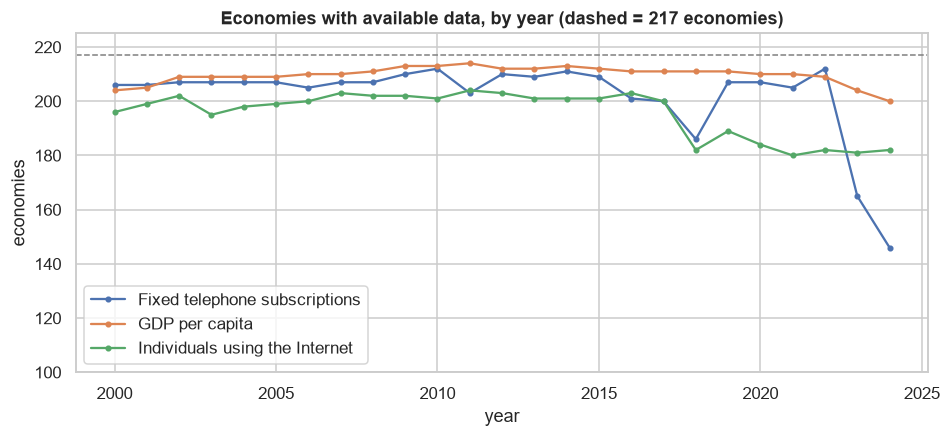

,Fixed telephone subscriptions,GDP per capita,Individuals using the Internet
year,,,
2000,206,204,196
2010,212,213,201
2018,186,211,182
2020,207,210,184
2022,212,209,182
2023,165,204,181
2024,146,200,182


In [39]:
# Number of economies reporting each indicator, by year
avail_counts = pd.DataFrame({LABEL[k].split(" (")[0]: avail[k].sum() for k in (FT, GDP, NET)})
ax = avail_counts.plot(figsize=(10, 4), marker="o", ms=3)
ax.axhline(n_econ, ls="--", c="grey", lw=1); ax.set_ylim(100, n_econ + 8)
ax.set_title("Economies with available data, by year (dashed = 217 economies)"); ax.set_ylabel("economies")
plt.show()
avail_counts.loc[[2000, 2010, 2018, 2020, 2022, 2023, 2024]]

**Observation.** GDP coverage stays close to the 217 maximum throughout. Internet use drops from about 201 economies to about 182 from 2018 onward. Fixed telephone is stable at 205–212 economies until 2022, apart from a one-year dip in 2018 (186), and then **falls sharply to 165 in 2023 and 146 in 2024**. 2024 is therefore not comparable with earlier years, which is why we use 2022 as the snapshot year.

In [40]:
# Which economies are missing, and Rwanda's data completeness
miss22 = names[ft[2022].isna()].tolist()
print(f"Fixed telephone missing in {SNAP} ({len(miss22)}):", miss22)
print(f"Fixed telephone missing in 2024 -> {int(ft[2024].isna().sum())} economies; by region:")
print(region[ft[2024].isna()].value_counts().to_string())
print()
print("Rwanda missing values by indicator:", panel[panel.iso3 == "RWA"][[FT, GDP, NET]].isna().sum().to_dict())
print("Rwanda years with a missing Internet value:", panel[(panel.iso3 == 'RWA') & panel[NET].isna()]["year"].tolist())

Fixed telephone missing in 2022 (5): ['Channel Islands', 'Dominica', 'Isle of Man', 'St. Martin (French part)', 'Sint Maarten (Dutch part)']
Fixed telephone missing in 2024 -> 71 economies; by region:
region
Latin America & Caribbean                            18
East Asia & Pacific                                  17
Sub-Saharan Africa                                   15
Europe & Central Asia                                13
Middle East, North Africa, Afghanistan & Pakistan     8

Rwanda missing values by indicator: {'fixed_tel': 0, 'gdp_pc': 0, 'internet': 1}
Rwanda years with a missing Internet value: [2006]


**Observation.** Only 5 small economies lack a 2022 fixed-telephone value, all island territories (Channel Islands, Dominica, Isle of Man, St. Martin, Sint Maarten). In 2024, 71 are missing, spread across five regions (Latin America & Caribbean 18, East Asia & Pacific 17, Sub-Saharan Africa 15, Europe & Central Asia 13, Middle East group 8), so the gap is general rather than regional. Rwanda's record is complete except Internet use in 2006.

In [41]:
# Exact zero values in fixed telephone subscriptions
zeros = panel[panel[FT] == 0][["country", "iso3", "region", "year", FT]]
print("Exact zero values:", len(zeros), "| economies:", zeros["iso3"].nunique())
(zeros.groupby(["country"])["year"].agg(lambda s: f"{s.min()}-{s.max()} ({len(s)} yrs)")
      .sort_values().to_frame("zero years").head(25))

Exact zero values: 52 | economies: 8


,zero years
country,
Guinea-Bissau,2010-2022 (10 yrs)
Naoero,2010-2022 (6 yrs)
Guinea,2012-2022 (9 yrs)
South Sudan,2013-2023 (8 yrs)
"Congo, Dem. Rep.",2013-2024 (12 yrs)
Kiribati,2018-2022 (4 yrs)
Chad,2023-2024 (2 yrs)
Bhutan,2024-2024 (1 yrs)


**Observation.** There are 52 exact zeros in 8 economies. They appear as unbroken runs, mostly in the 2010s and 2020s (e.g. DR Congo 2013–2024, Guinea-Bissau 2010–2022), which looks more like a reporting convention or rounding of very small values than every fixed line disappearing. We keep them as reported but treat them with caution.

In [42]:
# Outliers by the 1.5 x IQR rule (reported, not removed)
def iqr_outliers(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); i = q3 - q1
    return s[(s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)].sort_values(ascending=False)

out_rows = []
for k in (FT, GDP, NET):
    for y in (2000, SNAP):
        o = iqr_outliers(wide[k][y].dropna())
        out_rows.append({"Indicator": k, "Year": y, "n": int(wide[k][y].count()), "Outliers": len(o),
                         "Largest (top 5)": ", ".join(f"{names[i]} ({v:,.1f})" for i, v in o.head(5).items())})
pd.DataFrame(out_rows).set_index(["Indicator", "Year"])

n  Outliers                                    Largest (top 5)
Indicator Year                                                                  
fixed_tel 2000  206         3  Monaco (92.3), Bermuda (91.1), Cayman Islands ...
          2022  212         4  Monaco (109.6), Virgin Islands (U.S.) (87.7), ...
gdp_pc    2000  204        15  Monaco (81,789.0), Liechtenstein (76,087.9), B...
          2022  209        16  Monaco (226,052.1), Liechtenstein (188,055.0),...
internet  2000  196        27  Norway (52.0), Canada (51.3), San Marino (48.8...
          2022  182         1                                      Burundi (7.1)

**Observation.** Fixed telephone has few outliers (3 in 2000, 4 in 2022), led by Monaco and Bermuda / the U.S. Virgin Islands. GDP per capita has 15–16, all small high-income economies (Monaco US$226,052, Liechtenstein US$188,055 in 2022). Internet use had 27 outliers in 2000 (Norway 52%, Canada 51%) because those early adopters were far ahead of everyone else; by 2022 only Burundi (7.1%) is an outlier, now on the low side. Outliers are real values and are not removed.

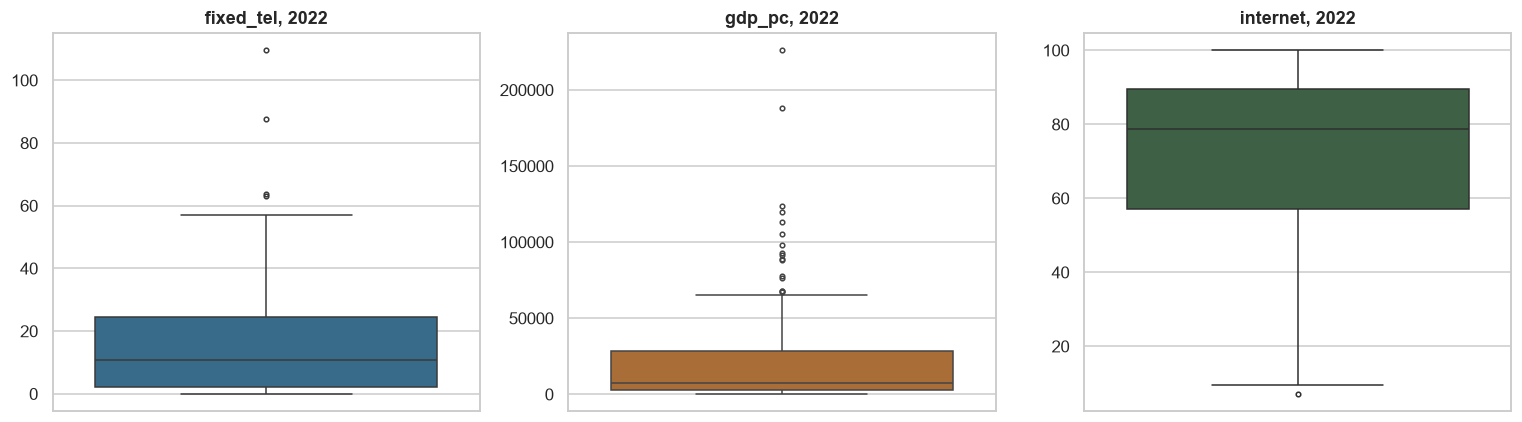

In [43]:
# Box plots of each indicator, 2022
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, k, c in zip(axes, (FT, GDP, NET), ("#2a6f97", "#bc6c25", "#386641")):
    sns.boxplot(y=wide[k][SNAP].dropna(), ax=ax, color=c, fliersize=3)
    ax.set_title(f"{k}, {SNAP}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Observation.** Fixed telephone: the box sits low (2–24) with a few points above 60. GDP per capita: the box is squeezed at the bottom and a long row of high outliers extends above US$65,000. Internet use: the box is high (57–90%) and the only outlier is at the bottom. The three variables therefore have very different shapes, which is why we compare medians and use rank correlations.

## 5e. Trends, patterns and relationships

### Trend 1: Regional medians over time

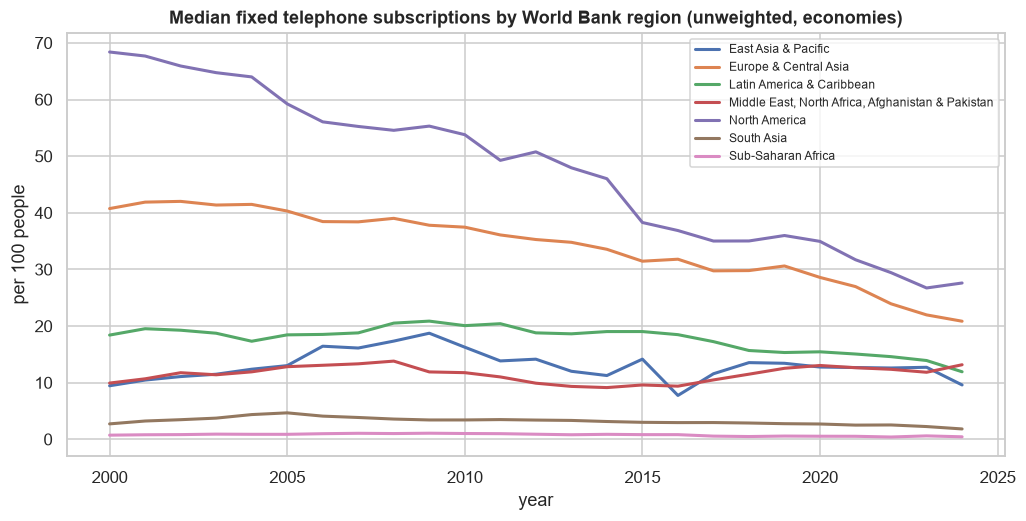

In [44]:
# Median fixed telephone subscriptions by region and year
reg_med = panel.groupby(["region", "year"])[FT].median().unstack(0)
ax = reg_med.plot(figsize=(11, 5), lw=2)
ax.set_title("Median fixed telephone subscriptions by World Bank region (unweighted, economies)")
ax.set_ylabel("per 100 people"); ax.legend(fontsize=8, loc="upper right", frameon=True); plt.show()

**Observation.** North America (68.4 → about 27) and Europe & Central Asia (40.7 → about 21) decline almost continuously across the period. Latin America stays near 15–20 until about 2015 and then eases down. East Asia & Pacific and the Middle East group rise slightly to around 2008–2009 and then hover at 10–15. South Asia (about 2–4) and Sub-Saharan Africa (below 1) are almost flat near zero. The last two points (2023–2024) rest on fewer economies and should not be read as new trends.

### Trend 2: Comparing two countries (Rwanda vs Kenya) and the region

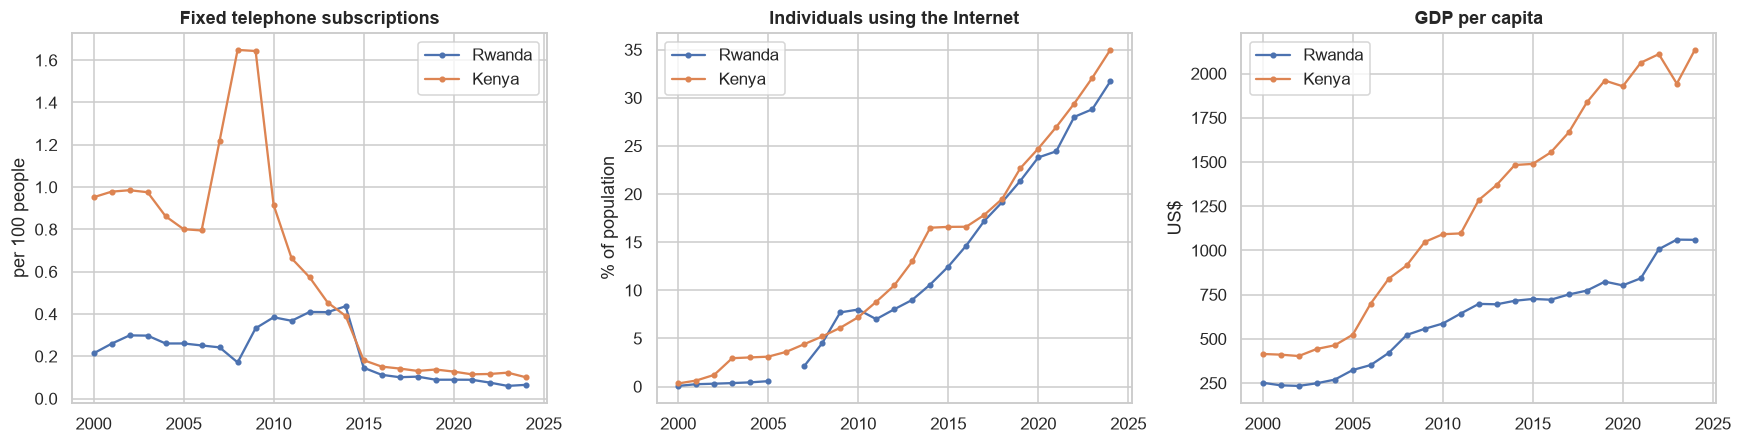

year,2000,2005,2010,2015,2020,2022,2024
iso3,,,,,,,
Rwanda,0.21,0.26,0.38,0.15,0.09,0.08,0.06
Kenya,0.95,0.80,0.92,0.18,0.13,0.12,0.10


In [45]:
# Rwanda vs Kenya on the three indicators
pair = ["RWA", "KEN"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, k in zip(axes, (FT, NET, GDP)):
    for c in pair:
        ax.plot(wide[k].columns, wide[k].loc[c], marker="o", ms=3, label=names[c])
    ax.set_title(LABEL[k].split(" (")[0]); ax.legend()
axes[1].set_ylabel("% of population"); axes[0].set_ylabel("per 100 people"); axes[2].set_ylabel("US$")
plt.tight_layout(); plt.show()
wide[FT].loc[pair, [2000, 2005, 2010, 2015, 2020, 2022, 2024]].rename(index=names)

**Observation.** Both countries have under 2 lines per 100 people throughout. **Kenya** rose sharply to 1.65 in 2008–2009 and then fell to 0.92 in 2010 and 0.18 in 2015. **Rwanda** rose slowly to 0.44 in 2014 and then dropped by about two thirds in one year (0.15 in 2015). Both ended near 0.1 in 2022. Over the same years Internet use rose in both from almost zero to over 30%, and Kenya's GDP per capita stayed about twice Rwanda's. The single-year drops look like network or definition changes; the data cannot tell us which.

### Trend 3: Abrupt rises and falls (Q6, touched on here because it explains data quality)

In [46]:
# Largest one-year changes, flagged when next to a missing year or a zero
sub = ft.loc[:, START:END]
d1 = sub.diff(axis=1)
flag = sub.isna() | (sub == 0)
near = flag | flag.shift(1, axis=1, fill_value=False) | flag.shift(-1, axis=1, fill_value=False)
d1_long = d1.stack().rename("change").reset_index()
d1_long.columns = ["iso3", "year", "change"]
d1_long["near gap/zero"] = near.stack().reindex(pd.MultiIndex.from_frame(d1_long[["iso3", "year"]])).values
d1_long["country"] = d1_long["iso3"].map(names)
big = d1_long.reindex(d1_long["change"].abs().sort_values(ascending=False).index).head(12)
big[["country", "year", "change", "near gap/zero"]].reset_index(drop=True)

,country,year,change,near gap/zero
0,Bermuda,2014,-67.24,False
1,British Virgin Islands,2019,38.54,False
2,Bermuda,2015,-27.11,False
3,French Polynesia,2023,-25.99,True
4,Monaco,2009,23.48,False
5,Greenland,2007,-22.47,False
6,Naoero,2010,-18.97,True
7,Tonga,2014,-17.69,False
8,British Virgin Islands,2003,16.82,False
9,Monaco,2024,-15.55,False


**Observation.** Of the 12 largest one-year changes, 10 are **not** next to a missing year or a zero, so they are not just reporting gaps. Bermuda fell by 67.2 in 2014 and 27.1 in 2015; the British Virgin Islands rose by 38.5 in 2019; Monaco rose 23.5 in 2009 and fell 15.6 in 2024. Only French Polynesia (2023) and Nauru (2010) are flagged. Almost all are small economies, where one operator or a change in definition can move the national figure. This partly answers preliminary **Q6**.

## 5f. Answering the eight final questions

### Q1 ★ How did the median fixed telephone subscriptions change from 2000 to 2024, and did it peak?

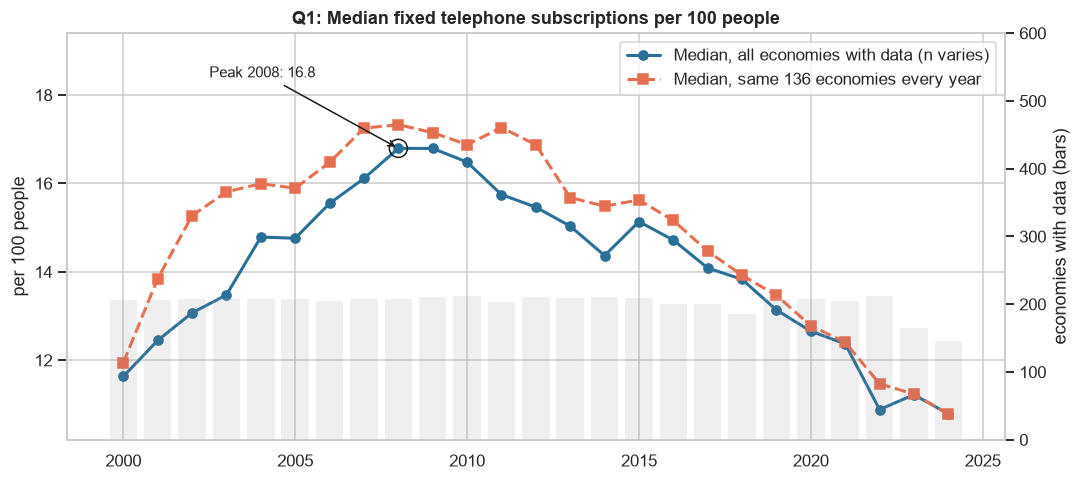

,median (all),n economies,median (same 136)
year,,,
2000,11.63,206,11.94
2005,14.76,207,15.89
2010,16.48,212,16.88
2015,15.14,209,15.63
2020,12.66,207,12.78
2022,10.88,212,11.47
2023,11.22,165,11.23
2024,10.78,146,10.78


In [47]:
# Q1: yearly median for all economies vs the 136 with complete data
med = ft.loc[:, START:END].median()
n_year = ft.loc[:, START:END].count()
balanced_ids = ft.loc[:, START:END].dropna().index
med_bal = ft.loc[balanced_ids, START:END].median()
peak_year, peak_val = med.idxmax(), med.max()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(med.index, med.values, marker="o", lw=2, label="Median, all economies with data (n varies)", color="#2a6f97")
ax.plot(med_bal.index, med_bal.values, marker="s", lw=2, ls="--", label=f"Median, same {len(balanced_ids)} economies every year", color="#e76f51")
ax.scatter([peak_year], [peak_val], s=140, facecolor="none", edgecolor="k", zorder=5)
ax.annotate(f"Peak {peak_year}: {peak_val:.1f}", xy=(peak_year, peak_val), xytext=(2002.5, 18.4),
            arrowprops=dict(arrowstyle="->", color="k"), fontsize=10)
ax.set_ylim(10.2, 19.4)
ax.set_ylabel("per 100 people"); ax.set_title("Q1: Median fixed telephone subscriptions per 100 people")
ax2 = ax.twinx(); ax2.bar(n_year.index, n_year.values, alpha=.12, color="grey"); ax2.set_ylim(0, 600); ax2.set_ylabel("economies with data (bars)"); ax2.grid(False)
ax.legend(loc="upper right"); plt.show()

q1 = pd.DataFrame({"median (all)": med, "n economies": n_year, f"median (same {len(balanced_ids)})": med_bal})
q1.loc[[2000, 2005, 2010, 2015, 2020, 2022, 2023, 2024]]

**Observation.** The solid line (all reporting economies) climbs from 11.6 in 2000 to its highest point in 2008 and then falls almost every year to about 10.9 in 2022. The dashed line, using only the 136 economies with complete data, follows the same rise-then-fall shape, so the pattern is not caused by economies entering or leaving the data. The grey bars show the drop in reporting economies in 2023–2024.

In [48]:
# Key numbers for Q1
print(f"Peak of the all-economy median: {peak_val:.2f} in {peak_year}")
print(f"Peak of the balanced-set median: {med_bal.max():.2f} in {med_bal.idxmax()}")
print(f"2000: {med[2000]:.2f}  ->  2022: {med[2022]:.2f}  ->  2024: {med[2024]:.2f} (n={n_year[2024]})")

Peak of the all-economy median: 16.79 in 2008
Peak of the balanced-set median: 17.33 in 2008
2000: 11.63  ->  2022: 10.88  ->  2024: 10.78 (n=146)


**Answer to Q1.** The median fixed telephone subscription rate **rose from 11.6 per 100 people in 2000 to a peak of 16.8 in 2008**, then **fell steadily to 10.9 in 2022**, below its 2000 level (a rise of about 44% followed by a fall of about 35%). Using only the 136 economies with complete data gives the same shape (peak 17.3 in 2008), so the pattern is not caused by the changing set of reporting economies. The 2024 median (10.8) rests on only 146 economies and should not be read as a new trend.

### Q3 ★ Which economies had the largest increases and declines between 2000 and 2022?

Economies with data in both years: 205
Increased: 61 | Declined: 144 | No change: 0
Median change: -0.86 per 100 people


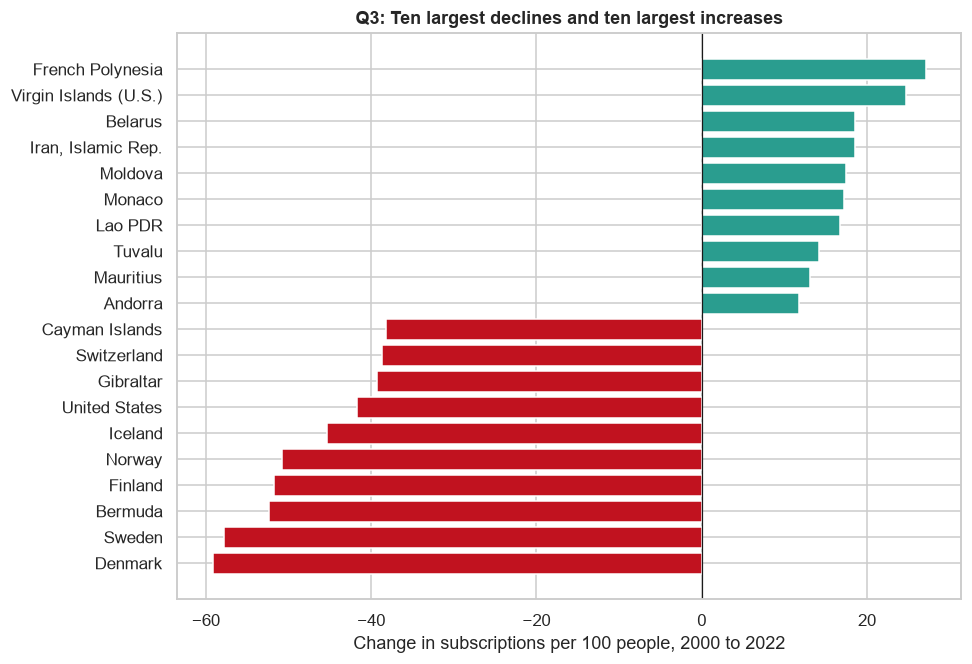


Ten largest increases:


,2000,2022,change,region
country,,,,
French Polynesia,22.34,49.45,27.11,East Asia & Pacific
Virgin Islands (U.S.),62.89,87.66,24.78,Latin America & Caribbean
Belarus,27.54,46.11,18.57,Europe & Central Asia
"Iran, Islamic Rep.",14.28,32.78,18.49,"Middle East, North Africa, Afghanistan & Pakistan"
Moldova,13.79,31.29,17.50,Europe & Central Asia
Monaco,92.34,109.55,17.21,Europe & Central Asia
Lao PDR,0.75,17.54,16.78,East Asia & Pacific
Tuvalu,6.92,21.15,14.23,East Asia & Pacific
Mauritius,23.09,36.21,13.12,Sub-Saharan Africa


Ten largest declines:


,2000,2022,change,region
country,,,,
Denmark,71.82,12.66,-59.16,Europe & Central Asia
Sweden,68.26,10.47,-57.79,Europe & Central Asia
Bermuda,91.10,38.70,-52.40,North America
Finland,55.04,3.25,-51.79,Europe & Central Asia
Norway,53.46,2.66,-50.80,Europe & Central Asia
Iceland,69.80,24.46,-45.34,Europe & Central Asia
United States,68.39,26.63,-41.76,North America
Gibraltar,84.96,45.61,-39.34,Europe & Central Asia
Switzerland,72.88,34.17,-38.71,Europe & Central Asia


In [49]:
# Q3: change in subscriptions per economy, 2000 to 2022
chg = (ft[2022] - ft[2000]).dropna().rename("change")
print("Economies with data in both years:", len(chg))
print(f"Increased: {(chg > 0).sum()} | Declined: {(chg < 0).sum()} | No change: {(chg == 0).sum()}")
print(f"Median change: {chg.median():.2f} per 100 people")

top = chg.sort_values()
sel = pd.concat([top.head(10), top.tail(10)])
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.barh([names[i] for i in sel.index], sel.values, color=["#c1121f" if v < 0 else "#2a9d8f" for v in sel.values])
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("Change in subscriptions per 100 people, 2000 to 2022")
ax.set_title("Q3: Ten largest declines and ten largest increases"); plt.tight_layout(); plt.show()

tbl = pd.DataFrame({"2000": ft[2000], "2022": ft[2022], "change": chg}).dropna()
tbl["country"] = tbl.index.map(names); tbl["region"] = tbl.index.map(region)
print("\nTen largest increases:"); display(tbl.sort_values("change", ascending=False).head(10).set_index("country"))
print("Ten largest declines:"); display(tbl.sort_values("change").head(10).set_index("country"))

**Observation.** The red bars (declines) are much longer than the green bars (increases): the largest decline, Denmark (−59.2), is more than twice the largest increase, French Polynesia (+27.1). Most large declines are in Europe & Central Asia and North America, while the increases are spread across regions and are mostly in small economies.

**Answer to Q3.** Of the 205 economies with data in both years, **144 (70%) declined** and 61 increased; the median change was −0.9 lines per 100 people.
* **Largest declines:** Denmark (−59.2, from 71.8 to 12.7), Sweden (−57.8), Bermuda (−52.4), Finland (−51.8), Norway (−50.8), Iceland (−45.3), the United States (−41.8), Gibraltar, Switzerland and the Cayman Islands. These are almost all high-income economies that started with very high rates.
* **Largest increases:** French Polynesia (+27.1), U.S. Virgin Islands (+24.8), Belarus (+18.6), Iran (+18.5), Moldova (+17.5), Monaco (+17.2), Lao PDR (+16.8, from a base of 0.75), Tuvalu, Mauritius and Andorra.
* Note that absolute changes depend on the starting level: an economy near zero cannot fall by 50, so the biggest declines are necessarily found among economies that began high.

### Q4 ★ When did each economy peak (2000–2022), and how far below that peak was 2022?

Economies with a 2022 value and at least one earlier value: 212
Peaked in 2022 (gap = 0): 16
Median 2022 value as % of own peak: 52.7%
Median peak year: 2008


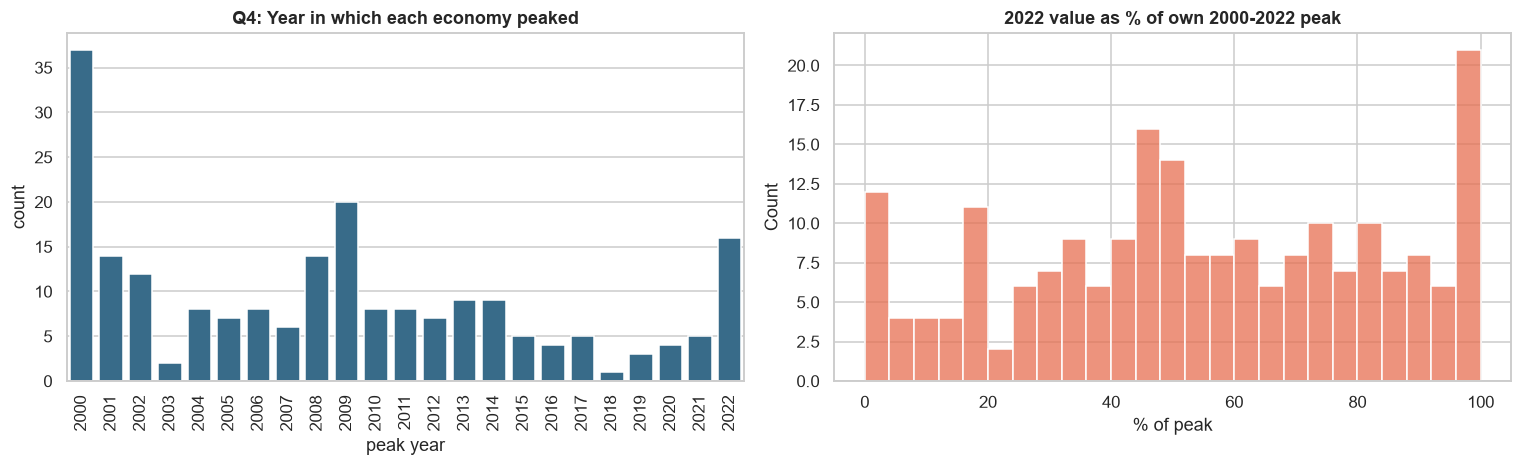

In [50]:
# Q4: each economy's peak year and its 2022 value as a % of that peak
win = ft.loc[:, START:SNAP]
ok = win.notna().sum(axis=1) > 0
peak_val_e = win.max(axis=1)[ok]
peak_yr_e = win[ok].idxmax(axis=1)
v22 = ft[SNAP][ok]
q4 = pd.DataFrame({"peak_year": peak_yr_e, "peak_value": peak_val_e, "value_2022": v22})
q4 = q4.dropna(subset=["value_2022"])
q4["gap_abs"] = q4["peak_value"] - q4["value_2022"]
q4["pct_of_peak"] = np.where(q4["peak_value"] > 0, 100 * q4["value_2022"] / q4["peak_value"], np.nan)
q4["country"] = q4.index.map(names)
print("Economies with a 2022 value and at least one earlier value:", len(q4))
print("Peaked in 2022 (gap = 0):", int((q4["gap_abs"] == 0).sum()))
print(f"Median 2022 value as % of own peak: {q4['pct_of_peak'].median():.1f}%")
print(f"Median peak year: {q4['peak_year'].median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.countplot(x=q4["peak_year"].astype(int), ax=axes[0], color="#2a6f97")
axes[0].set_title("Q4: Year in which each economy peaked"); axes[0].tick_params(axis="x", rotation=90); axes[0].set_xlabel("peak year")
sns.histplot(q4["pct_of_peak"].dropna(), bins=25, ax=axes[1], color="#e76f51")
axes[1].set_title("2022 value as % of own 2000-2022 peak"); axes[1].set_xlabel("% of peak")
plt.tight_layout(); plt.show()

**Observation.** The peak-year chart has two clusters: 37 economies peaked in 2000 (the first year of our window, so their true peak may be earlier) and a second group around 2008–2009. 16 economies peaked in 2022. The right chart shows that 2022 values range from almost 0% to 100% of each economy's own peak, with a concentration around 40–50% and a group at 100% (still at peak).

In [51]:
# Q4: by region, largest shortfalls, economies still at their peak
print("Peak-year summary by region (median peak year, median % of peak remaining):")
q4["region"] = q4.index.map(region)
rp = q4.groupby("region").agg(economies=("peak_year", "size"), median_peak_year=("peak_year", "median"),
                              median_pct_of_peak=("pct_of_peak", "median"))
rp["median_peak_year"] = rp["median_peak_year"].round().astype(int)
display(rp)
print("Ten economies furthest below their own peak (percentage points of subscriptions lost):")
display(q4.sort_values("gap_abs", ascending=False).head(10)[["country", "peak_year", "peak_value", "value_2022", "gap_abs", "pct_of_peak"]].set_index("country"))
print("Economies still at their peak in 2022 (peak_year == 2022):")
print(q4[q4["peak_year"] == SNAP]["country"].tolist())

Peak-year summary by region (median peak year, median % of peak remaining):


,economies,median_peak_year,median_pct_of_peak
region,,,
East Asia & Pacific,37,2009,51.69
Europe & Central Asia,57,2005,52.63
Latin America & Caribbean,39,2009,59.72
"Middle East, North Africa, Afghanistan & Pakistan",22,2013,70.98
North America,3,2001,38.94
South Asia,6,2008,47.29
Sub-Saharan Africa,48,2009,30.77


Ten economies furthest below their own peak (percentage points of subscriptions lost):


,peak_year,peak_value,value_2022,gap_abs,pct_of_peak
country,,,,,
Bermuda,2013,113.25,38.70,74.55,34.17
Denmark,2001,72.12,12.66,59.46,17.56
Sweden,2000,68.26,10.47,57.79,15.33
Greenland,2006,63.26,8.92,54.33,14.11
Finland,2000,55.04,3.25,51.79,5.91
Norway,2000,53.46,2.66,50.80,4.98
Iceland,2000,69.80,24.46,45.34,35.05
Gibraltar,2001,88.63,45.61,43.01,51.47
Cayman Islands,2001,92.48,49.97,42.51,54.03


Economies still at their peak in 2022 (peak_year == 2022):
['Afghanistan', 'Andorra', 'Brunei Darussalam', 'Cuba', 'Algeria', 'Mexico', 'Mongolia', 'Malaysia', 'Portugal', 'French Polynesia', 'Saudi Arabia', 'Tunisia', 'Tuvalu', 'Uruguay', 'Virgin Islands (U.S.)', 'Kosovo']


**Answer to Q4.** The typical economy peaked **around 2008** (median peak year) and by 2022 stood at a **median of 52.7% of its own peak**. About a quarter of economies peaked in 2000–2001, i.e. at or before the start of our window, so their true peak may be earlier. Only **16 economies were still at their peak in 2022**: Afghanistan, Andorra, Brunei Darussalam, Cuba, Algeria, Mexico, Mongolia, Malaysia, Portugal, French Polynesia, Saudi Arabia, Tunisia, Tuvalu, Uruguay, the U.S. Virgin Islands and Kosovo.
* By region, 2022 was furthest below peak in **Sub-Saharan Africa (median 30.8% of peak)** and North America (38.9%, three economies), and closest in the Middle East/North Africa/Afghanistan/Pakistan group (71.0%).
* Largest absolute shortfalls from peak: Bermuda (113.3 in 2013 to 38.7), Denmark (72.1 in 2001 to 12.7), Sweden, Greenland, Finland (5.9% of its peak left) and Norway (5.0%).

### Q5 ★ Regional differences in 2000 and 2022

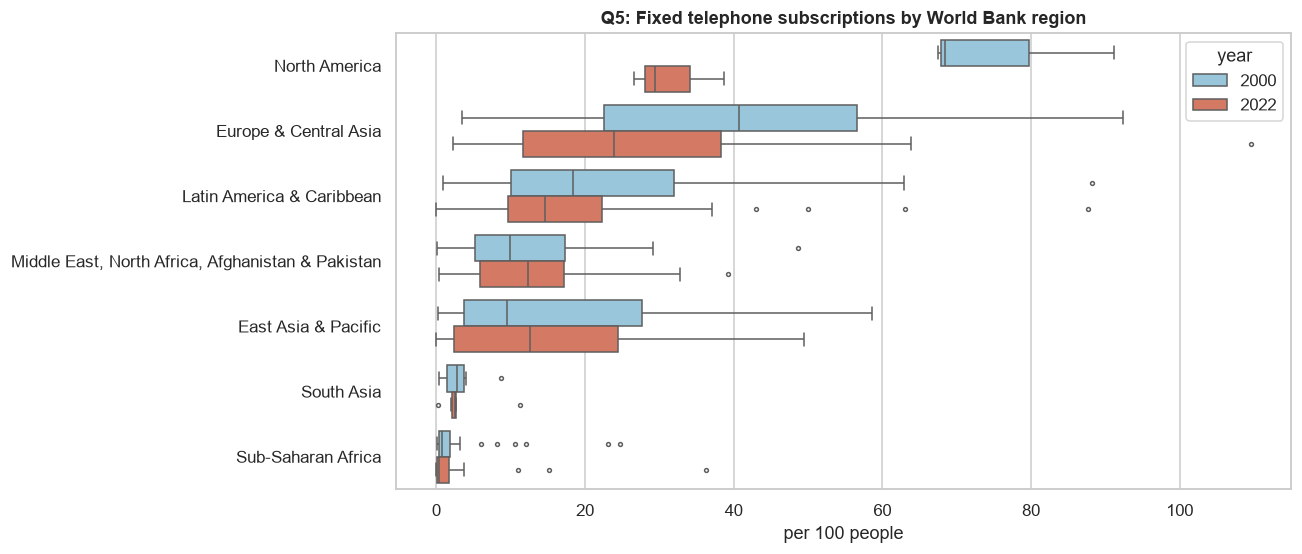

,n 2000,median 2000,n 2022,median 2022,change in median
region,,,,,
North America,3,68.39,3,29.42,-38.97
Europe & Central Asia,54,40.74,57,23.92,-16.82
Latin America & Caribbean,39,18.40,39,14.59,-3.81
"Middle East, North Africa, Afghanistan & Pakistan",22,9.93,22,12.35,2.43
East Asia & Pacific,35,9.45,37,12.59,3.14
South Asia,6,2.72,6,2.53,-0.19
Sub-Saharan Africa,47,0.73,48,0.40,-0.33


In [52]:
# Q5: regional distributions and medians, 2000 vs 2022
reg_df = panel[panel["year"].isin([2000, SNAP])].dropna(subset=[FT]).copy()
order = (reg_df[reg_df.year == 2000].groupby("region")[FT].median().sort_values(ascending=False)).index
fig, ax = plt.subplots(figsize=(12, 5.2))
sns.boxplot(data=reg_df, y="region", x=FT, hue="year", order=order, palette=["#8ecae6", "#e76f51"], ax=ax, fliersize=2.5)
ax.set_title("Q5: Fixed telephone subscriptions by World Bank region"); ax.set_xlabel("per 100 people"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

g = reg_df.groupby(["region", "year"])[FT].agg(n="count", median="median", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)).unstack()
rt = pd.DataFrame({"n 2000": g[("n", 2000)], "median 2000": g[("median", 2000)],
                   "n 2022": g[("n", SNAP)], "median 2022": g[("median", SNAP)]})
rt["change in median"] = rt["median 2022"] - rt["median 2000"]
rt = rt.loc[order]; rt

**Observation.** North America shows the largest shift: its box moved from about 68–80 lines in 2000 to about 28–34 in 2022. Europe & Central Asia's box also moved clearly to the left, and Latin America's narrowed. The Middle East group and East Asia & Pacific moved slightly to the right. South Asia and Sub-Saharan Africa stay squeezed near zero in both years; Sub-Saharan Africa's few high points are Mauritius, Seychelles and Cabo Verde.

In [53]:
# Q5: gap between highest and lowest region, and change in ranking
print(f"Spread between highest and lowest regional medians:  2000 = {rt['median 2000'].max() - rt['median 2000'].min():.1f}  |  {SNAP} = {rt['median 2022'].max() - rt['median 2022'].min():.1f}")
print("Rank of regions (1 = highest median):")
pd.DataFrame({"rank 2000": rt["median 2000"].rank(ascending=False), "rank 2022": rt["median 2022"].rank(ascending=False)})

Spread between highest and lowest regional medians:  2000 = 67.7  |  2022 = 29.0
Rank of regions (1 = highest median):


,rank 2000,rank 2022
region,,
North America,1.00,1.00
Europe & Central Asia,2.00,2.00
Latin America & Caribbean,3.00,3.00
"Middle East, North Africa, Afghanistan & Pakistan",4.00,5.00
East Asia & Pacific,5.00,4.00
South Asia,6.00,6.00
Sub-Saharan Africa,7.00,7.00


**Answer to Q5.** In both years the ranking is led by **North America** and **Europe & Central Asia**, with **Sub-Saharan Africa lowest** (0.73 in 2000 and 0.40 in 2022).
* **Medians (2000 → 2022):** North America 68.4 → 29.4; Europe & Central Asia 40.7 → 23.9; Latin America & Caribbean 18.4 → 14.6; Middle East/North Africa/Afghanistan/Pakistan 9.9 → 12.4; East Asia & Pacific 9.5 → 12.6; South Asia 2.7 → 2.5; Sub-Saharan Africa 0.73 → 0.40.
* The **gap between the highest and lowest regional medians narrowed from 67.7 to 29.0**, but this is a **convergence from the top** (the high regions fell), not from the bottom: Sub-Saharan Africa and South Asia did not improve. Only the Middle East group and East Asia & Pacific rose, and they swapped fourth and fifth place. Relative to Sub-Saharan Africa, North America was about 94 times higher in 2000 and about 74 times higher in 2022.
* Caution: North America has only three economies (Bermuda, Canada, the United States) and South Asia six, so their medians are fragile.

### Q7 ★ Fixed telephone subscriptions vs GDP per capita, 2022 (linear vs log scale)

Economies with both values in 2022: 205


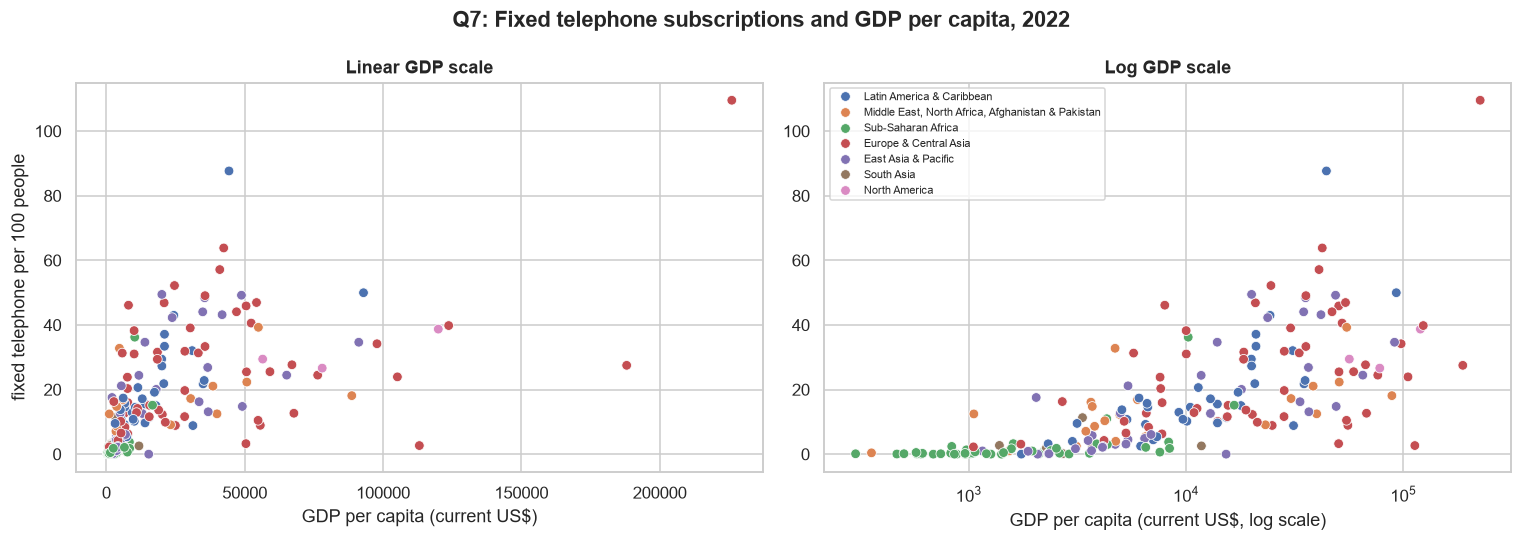

Spearman rho (rank, scale-free): 0.80  (p=5.4e-47)
Pearson r, linear GDP:           0.61
Pearson r, log10 GDP:            0.69


In [54]:
# Q7: fixed telephone vs GDP per capita, linear and log scale
q7 = pd.DataFrame({FT: ft[SNAP], GDP: gdp[SNAP]}).dropna()
q7["log10_gdp"] = np.log10(q7[GDP]); q7["region"] = q7.index.map(region); q7["country"] = q7.index.map(names)
print("Economies with both values in 2022:", len(q7))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=q7, x=GDP, y=FT, hue="region", ax=axes[0], s=40, legend=False)
axes[0].set_title("Linear GDP scale"); axes[0].set_xlabel("GDP per capita (current US$)"); axes[0].set_ylabel("fixed telephone per 100 people")
sns.scatterplot(data=q7, x=GDP, y=FT, hue="region", ax=axes[1], s=40)
axes[1].set_xscale("log"); axes[1].set_title("Log GDP scale"); axes[1].set_xlabel("GDP per capita (current US$, log scale)"); axes[1].set_ylabel("")
axes[1].legend(fontsize=7, loc="upper left")
fig.suptitle("Q7: Fixed telephone subscriptions and GDP per capita, 2022", fontweight="bold"); plt.tight_layout(); plt.show()

sp = stats.spearmanr(q7[GDP], q7[FT]); pl = stats.pearsonr(q7[GDP], q7[FT]); plog = stats.pearsonr(q7["log10_gdp"], q7[FT])
print(f"Spearman rho (rank, scale-free): {sp[0]:.2f}  (p={sp[1]:.2g})")
print(f"Pearson r, linear GDP:           {pl[0]:.2f}")
print(f"Pearson r, log10 GDP:            {plog[0]:.2f}")

**Observation.** On the linear axis most economies are squeezed into the left part of the chart and a few very rich economies (Monaco far right) stretch it, so the relationship looks weak and curved. On the log axis the points rise more steadily from left to right. The vertical spread widens with income: below about US$3,000 almost every economy has under 5 lines, while above US$30,000 values range from about 3 to 60. Spearman ρ = 0.80; Pearson r rises from 0.61 to 0.69 when GDP is logged.

In [55]:
# Q7: medians by GDP quartile, and economies far from the overall trend
q7["gdp_quartile"] = pd.qcut(q7[GDP], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
display(q7.groupby("gdp_quartile")[[GDP, FT]].median().join(q7.groupby("gdp_quartile").size().rename("n")))

print("Highest-GDP economies with unusually low subscriptions, and low-GDP ones with high subscriptions:")
resid = q7[FT] - np.polyval(np.polyfit(q7["log10_gdp"], q7[FT], 1), q7["log10_gdp"])
display(pd.concat([q7.loc[resid.sort_values().index[:5], ["country", GDP, FT]],
                   q7.loc[resid.sort_values().index[-5:], ["country", GDP, FT]]]).set_index("country"))

,gdp_pc,fixed_tel,n
gdp_quartile,,,
Q1 lowest,"1,236.97",0.36,52
Q2,"4,754.41",5.78,51
Q3,"15,309.83",15.51,51
Q4 highest,"50,440.56",27.66,51


Highest-GDP economies with unusually low subscriptions, and low-GDP ones with high subscriptions:


,gdp_pc,fixed_tel
country,,
Norway,"113,122.13",2.66
Finland,"50,440.56",3.25
Greenland,"55,635.00",8.92
Naoero,"15,309.83",0.00
Sweden,"54,836.89",10.47
France,"40,988.64",57.14
Belarus,"7,994.65",46.11
Andorra,"42,414.06",63.82
Virgin Islands (U.S.),"44,320.91",87.66


**Answer to Q7.** Across 205 economies in 2022, fixed telephone subscriptions are **positively and monotonically associated with GDP per capita** (Spearman ρ = 0.80). The pattern **does look different on a log scale**: on the linear axis most economies are bunched at the left (most below about US$50,000) because a few very rich economies stretch the axis, and the relationship looks weak and curved (Pearson r = 0.61); on the log axis the cloud rises more evenly (r = 0.69).
* Median subscriptions by GDP-per-capita quartile were 0.4, 5.8, 15.5 and 27.7 per 100 people from lowest to highest.
* The relationship is **asymmetric**: low income almost always goes with very few fixed lines, but high income does not guarantee many. Norway (US$113,122, only 2.7 lines), Finland (3.3) and Sweden (10.5) are rich with few lines, while Monaco (109.6), the U.S. Virgin Islands (87.7), Andorra (63.8) and Belarus (46.1, at a much lower income) have many.
* This is an association in one year; it does not show that income *causes* more lines. GDP is in current US$, so exchange-rate effects also enter the comparison.

### Q9 ★ Fixed telephone subscriptions vs Internet use, 2022

Economies with both values in 2022: 181


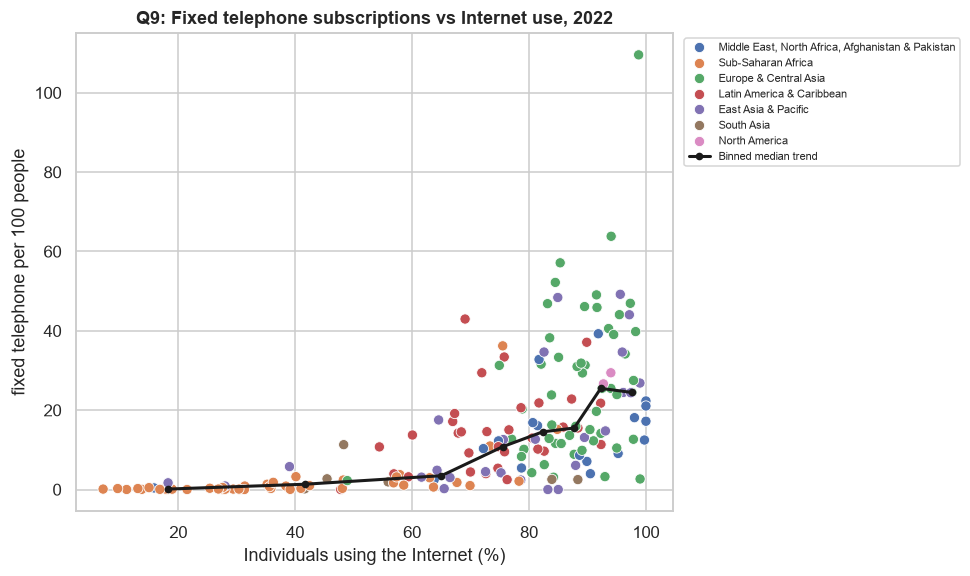

Spearman rho: 0.74 (p=6.1e-33) | Pearson r: 0.58


,n,median_fixed_tel,q1,q3
internet_band,,,,
0-25%,14,0.12,0.04,0.36
25-50%,28,0.42,0.12,1.45
50-75%,36,4.68,3.01,13.86
75-100%,103,17.21,10.33,32.32


In [56]:
# Q9: fixed telephone vs Internet use, 2022
def trend_line(ax, x, y, bins=8, color="k"):
    """Draw the median of y within equal-count bins of x."""
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    d["bin"] = pd.qcut(d["x"], bins, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(x=("x", "median"), y=("y", "median"))
    ax.plot(g["x"], g["y"], color=color, lw=2, marker="o", ms=4, label="Binned median trend")

q9 = pd.DataFrame({FT: ft[SNAP], NET: net[SNAP]}).dropna()
q9["region"] = q9.index.map(region); q9["country"] = q9.index.map(names)
print("Economies with both values in 2022:", len(q9))

fig, ax = plt.subplots(figsize=(9, 5.4))
sns.scatterplot(data=q9, x=NET, y=FT, hue="region", s=45, ax=ax)
trend_line(ax, q9[NET], q9[FT])
ax.set_title("Q9: Fixed telephone subscriptions vs Internet use, 2022"); ax.set_xlabel("Individuals using the Internet (%)"); ax.set_ylabel("fixed telephone per 100 people")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

sp = stats.spearmanr(q9[NET], q9[FT]); pr = stats.pearsonr(q9[NET], q9[FT])
print(f"Spearman rho: {sp[0]:.2f} (p={sp[1]:.2g}) | Pearson r: {pr[0]:.2f}")
q9["internet_band"] = pd.cut(q9[NET], [0, 25, 50, 75, 100], include_lowest=True, labels=["0-25%", "25-50%", "50-75%", "75-100%"])
q9.groupby("internet_band").agg(n=(FT, "size"), median_fixed_tel=(FT, "median"), q1=(FT, lambda s: s.quantile(.25)), q3=(FT, lambda s: s.quantile(.75)))

**Observation.** The black binned-median line stays close to zero until about 60% Internet use and then climbs to about 25 lines per 100 people above 90%. Below 50% Internet use almost every point is a Sub-Saharan African economy with under 2 lines. Above 75% the points spread from 0 to 64 lines (plus Monaco at 110), so high Internet use goes with many fixed lines in some economies and very few in others. The band table confirms the steps: median 0.12, 0.42, 4.7 and 17.2 lines for the four Internet bands.

In [57]:
# Q9: correlation within each region
by_reg = q9.groupby("region").apply(lambda d: pd.Series({"n": len(d), "Spearman rho": stats.spearmanr(d[NET], d[FT])[0] if len(d) > 4 else np.nan}))
by_reg

,n,Spearman rho
region,,
East Asia & Pacific,26.00,0.63
Europe & Central Asia,52.00,0.30
Latin America & Caribbean,32.00,0.37
"Middle East, North Africa, Afghanistan & Pakistan",18.00,0.59
North America,2.00,NaN
South Asia,6.00,0.09
Sub-Saharan Africa,45.00,0.74


**Answer to Q9.** In 2022, across 181 economies, fixed telephone subscriptions are **positively associated with Internet use** (Spearman ρ = 0.74; Pearson r = 0.58). Economies where under 25% of people use the Internet have a median of 0.12 lines per 100 people; at 25–50% it is 0.42, at 50–75% it is 4.7, and at 75–100% it is 17.2.
* The association is **strongest within Sub-Saharan Africa (ρ = 0.74)** and East Asia & Pacific (0.63), and **weak inside Europe & Central Asia (0.30)** and South Asia (0.09, six economies). Among the highest-Internet economies the spread is wide (IQR 10.3 to 32.3), and several of the most connected Nordic economies have very few fixed lines.
* The cross-sectional link most likely reflects general development (both measures are higher in richer, better-connected economies) rather than one service producing the other; the next question shows that the link does not carry over to changes over time.

### Q10 ★ Did economies with larger Internet increases (2000–2022) show rises, falls, or no clear pattern in fixed telephone subscriptions?

Economies with data for both changes: 175


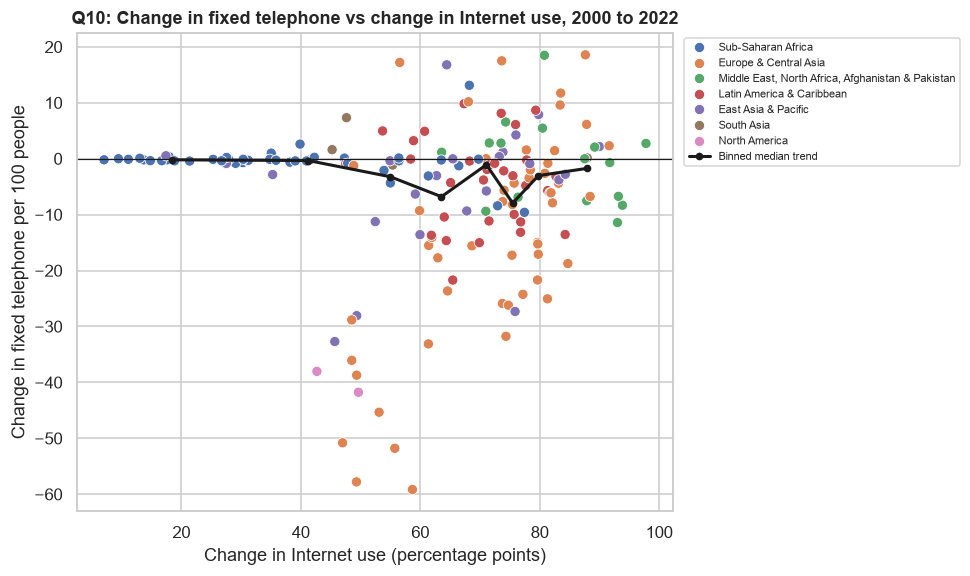

Spearman rho: -0.07 (p=0.38) | Pearson r: -0.00


,n,median_net_change,median_ft_change,share_with_ft_decline
net_change_quartile,,,,
Q1 smallest rise,44,30.73,-0.25,77.27
Q2,44,59.53,-4.31,81.82
Q3,43,73.64,-4.37,72.09
Q4 largest rise,44,82.61,-2.71,65.91


In [58]:
# Q10: change in Internet use vs change in fixed telephone, 2000 to 2022
q10 = pd.DataFrame({"d_net": net[SNAP] - net[2000], "d_ft": ft[SNAP] - ft[2000]}).dropna()
q10["region"] = q10.index.map(region); q10["country"] = q10.index.map(names)
print("Economies with data for both changes:", len(q10))

fig, ax = plt.subplots(figsize=(9, 5.4))
sns.scatterplot(data=q10, x="d_net", y="d_ft", hue="region", s=45, ax=ax)
ax.axhline(0, c="k", lw=.8)
trend_line(ax, q10["d_net"], q10["d_ft"])
ax.set_title("Q10: Change in fixed telephone vs change in Internet use, 2000 to 2022")
ax.set_xlabel("Change in Internet use (percentage points)"); ax.set_ylabel("Change in fixed telephone per 100 people")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

sp = stats.spearmanr(q10["d_net"], q10["d_ft"]); print(f"Spearman rho: {sp[0]:.2f} (p={sp[1]:.2g}) | Pearson r: {stats.pearsonr(q10['d_net'], q10['d_ft'])[0]:.2f}")
q10["net_change_quartile"] = pd.qcut(q10["d_net"], 4, labels=["Q1 smallest rise", "Q2", "Q3", "Q4 largest rise"])
q10.groupby("net_change_quartile").agg(n=("d_ft", "size"), median_net_change=("d_net", "median"), median_ft_change=("d_ft", "median"),
                                      share_with_ft_decline=("d_ft", lambda s: 100 * (s < 0).mean()))

**Observation.** Most points lie **below** the zero line (fixed lines fell). Points on the left (Internet increase under about 45 points) are mostly Sub-Saharan African economies with almost no change in fixed lines, because they had very few lines to lose. The largest declines (−30 to −60) sit at Internet increases of about 45–60 points: these are high-income economies such as Denmark, Sweden, Norway and the United States, which already had 37–52% Internet use in 2000 and so had less room to grow. The binned-median line moves between 0 and about −8 with no clear upward or downward slope (ρ = −0.07).

In [59]:
# Q10: correlation within each region
print("Spearman rho by region:")
display(q10.groupby("region").apply(lambda d: pd.Series({"n": len(d), "rho": stats.spearmanr(d["d_net"], d["d_ft"])[0] if len(d) > 4 else np.nan})))

Spearman rho by region:


,n,rho
region,,
East Asia & Pacific,24.00,0.32
Europe & Central Asia,50.00,0.54
Latin America & Caribbean,32.00,-0.15
"Middle East, North Africa, Afghanistan & Pakistan",16.00,-0.30
North America,2.00,NaN
South Asia,6.00,-0.31
Sub-Saharan Africa,45.00,-0.31


**Answer to Q10.** **There is no clear pattern.** For the 175 economies with data for both changes between 2000 and 2022, the rank correlation between the rise in Internet use and the change in fixed telephone subscriptions is **ρ = −0.07 (p = 0.38; Pearson r ≈ 0.00)**.
* Grouped by Internet-use change, the median change in fixed telephone subscriptions was −0.3, −4.3, −4.4 and −2.7 per 100 people for the smallest to largest Internet increases; the share with declining subscriptions was 77%, 82%, 72% and 66%. **Most economies lost fixed lines whatever their Internet growth.** The "smallest-rise" group shows almost no change in lines largely because many of those economies started near zero and had little to lose.
* Within regions the sign is inconsistent: positive in Europe & Central Asia (ρ = 0.54) and East Asia & Pacific (0.32), negative in Sub-Saharan Africa (−0.31), South Asia (−0.31), the Middle East group (−0.30) and Latin America (−0.15).
* The contrast with Q9 matters: economies with more Internet use *have* more fixed lines at a point in time, yet economies where Internet use grew more did **not** systematically lose or gain more lines. We therefore do not find support for a simple "Internet replaces fixed lines" story, but this analysis is descriptive and cannot rule out effects that act through other channels such as mobile telephony (not in our data).

### Q11 ★ Rwanda vs the median of the other Sub-Saharan African economies, 2000–2024

Sub-Saharan African economies: 48 | peers (excluding Rwanda): 47


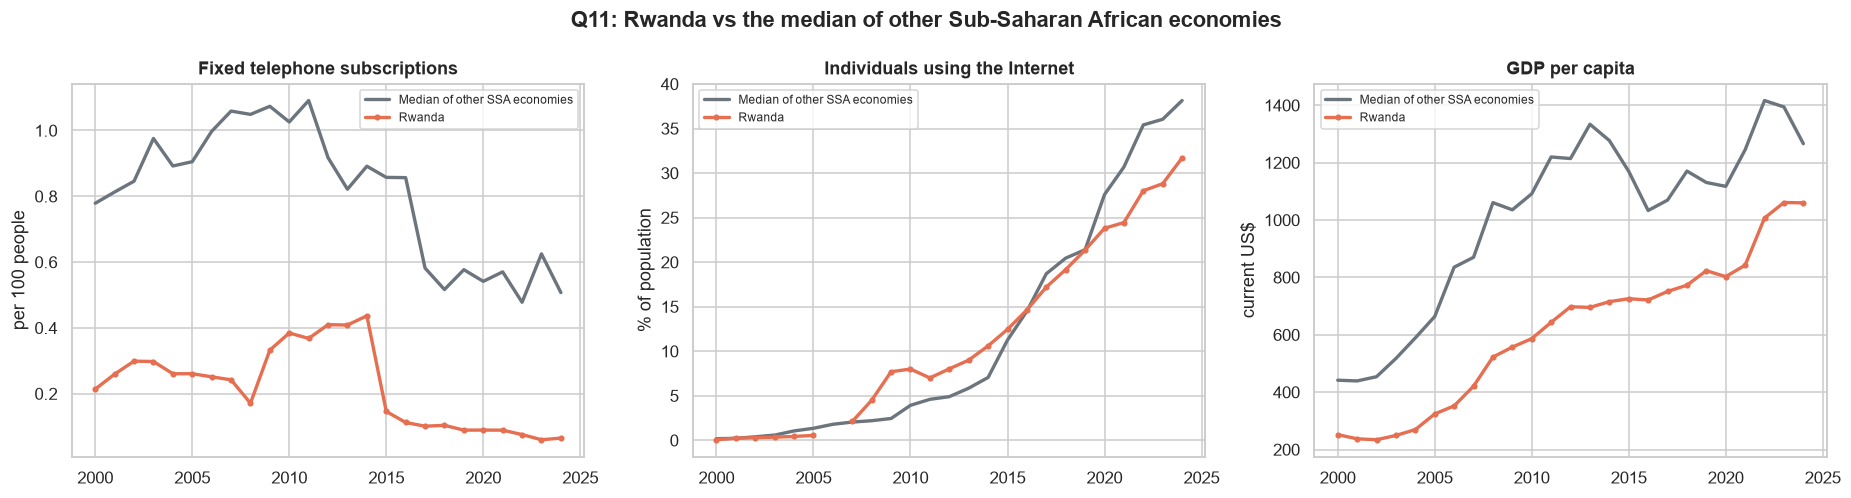

Rwanda                   Peer median                   Peers with data                
Indicator fixed_tel   gdp_pc internet   fixed_tel   gdp_pc internet       fixed_tel gdp_pc internet
Year                                                                                               
2000           0.21   251.87     0.06        0.78   441.60     0.18              46     46       46
2010           0.38   586.60     8.00        1.03 1,091.52     3.93              47     47       44
2020           0.09   802.64    23.80        0.54 1,117.42    27.58              44     45       44
2022           0.08 1,007.06    28.02        0.48 1,416.60    35.40              47     45       44
2024           0.06 1,059.94    31.70        0.51 1,266.09    38.14              32     45       44

In [60]:
# Q11: Rwanda vs the median of the other Sub-Saharan African economies
ssa_ids = region[region == "Sub-Saharan Africa"].index
peers = [i for i in ssa_ids if i != "RWA"]
print("Sub-Saharan African economies:", len(ssa_ids), "| peers (excluding Rwanda):", len(peers))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, k in zip(axes, (FT, NET, GDP)):
    peer_med = wide[k].loc[peers, START:END].median()
    ax.plot(peer_med.index, peer_med.values, lw=2.2, label="Median of other SSA economies", color="#6c757d")
    ax.plot(wide[k].columns[wide[k].columns >= START], wide[k].loc["RWA", START:END].values, lw=2.2, marker="o", ms=3, label="Rwanda", color="#e76f51")
    ax.set_title(LABEL[k].split(" (")[0]); ax.legend(fontsize=8)
axes[0].set_ylabel("per 100 people"); axes[1].set_ylabel("% of population"); axes[2].set_ylabel("current US$")
fig.suptitle("Q11: Rwanda vs the median of other Sub-Saharan African economies", fontweight="bold"); plt.tight_layout(); plt.show()

rows = []
for k in (FT, NET, GDP):
    pm = wide[k].loc[peers, START:END].median()
    for y in (2000, 2010, 2020, 2022, 2024):
        rows.append({"Indicator": k, "Year": y, "Rwanda": wide[k].loc["RWA", y], "Peer median": pm[y], "Peers with data": int(wide[k].loc[peers, y].count())})
q11 = pd.DataFrame(rows).pivot(index="Year", columns="Indicator")
q11

**Observation.** **Fixed telephone:** Rwanda's line is below the peer median in every year; the peer median rose to about 1.1 around 2011 and fell to about 0.5 after 2016, while Rwanda peaked at 0.44 in 2014 and dropped sharply in 2015. **Internet use:** Rwanda rose above the peer median from 2008 to 2015, was level in 2016 and fell behind from 2017, with the gap widening to 2024. **GDP per capita:** Rwanda is below the peer median throughout, but both lines rise and the gap narrows in relative terms (the peer median dips around 2016 and in 2024).

In [61]:
# Q11: Rwanda's rank within Sub-Saharan Africa (1 = highest)
rank_rows = []
for k in (FT, NET, GDP):
    for y in (2000, SNAP, 2024):
        s = wide[k].loc[ssa_ids, y].dropna()
        rank_rows.append({"Indicator": k, "Year": y, "Rwanda rank": int(s.rank(ascending=False)["RWA"]) if "RWA" in s.index else np.nan, "out of": len(s)})
pd.DataFrame(rank_rows).pivot(index="Year", columns="Indicator")

Rwanda rank                    out of                
Indicator   fixed_tel gdp_pc internet fixed_tel gdp_pc internet
Year                                                           
2000               44     39       38        47     47       47
2022               38     29       29        48     46       45
2024               28     30       29        33     46       45

**Answer to Q11.** (Peers = the 47 other Sub-Saharan African economies; peer coverage is shown in the table.)
* **Fixed telephone:** Rwanda has been **below the peer median in every year**: 0.21 vs 0.78 in 2000, 0.38 vs 1.03 in 2010, and 0.08 vs 0.48 in 2022 (roughly one sixth of the peer median). Rwanda's rate rose to a peak of 0.44 in 2014, then **fell by about two thirds in 2015 (to 0.15)** and stayed near 0.1 or below afterwards; the peer median also eased down over the 2010s. Rwanda's rank improved (44th of 47 in 2000 to 38th of 48 in 2022) mainly because other economies' lines fell too, not because Rwanda's own level rose. The 2024 peer median (0.51) uses only 32 peers and is not comparable.
* **Internet use:** Rwanda started below the peers (0.06% vs 0.18% in 2000), was **above** them from 2008 to 2015 (8.0% vs 3.9% in 2010; 12.5% vs 11.3% in 2015), was level in 2016 (14.6% vs 14.5%), and fell **behind** from 2017 (23.8% vs 27.6% in 2020; 31.7% vs 38.1% in 2024). Its rank moved from 38th (2000) to 29th (2022), so it improved in rank even while the gap to the peer median widened late in the period.
* **GDP per capita:** Rwanda is below the peer median throughout, but **the gap narrowed**: about 57% of the peer median in 2000 (US$252 vs US$442) and about 71% in 2022 (US$1,007 vs US$1,417). Its rank improved from 39th to 29th.
* Overall, Rwanda's income and Internet use grew relative to the region, but fixed telephony remained marginal and declined after 2010. Rwanda's own series is almost complete (Internet use in 2006 is the only gap).

# 6. Communicating Insights

### Key insights

1. **The fixed-telephone era peaked around 2008 and has been in retreat since.** The median economy went from 11.6 subscriptions per 100 people (2000) to 16.8 (2008) and back to 10.9 (2022), below where it started. The same shape appears in a fixed set of 136 economies with complete data.
2. **Declines were concentrated among high-income economies that started high.** 70% of economies lost fixed lines between 2000 and 2022; Denmark, Sweden, Finland, Norway and Bermuda lost 50–60 lines per 100 people. The typical economy now sits at about half of its own peak.
3. **Regional gaps narrowed from the top, not from the bottom.** The gap between the highest and lowest regional medians fell from 67.7 to 29.0, but Sub-Saharan Africa (0.4) and South Asia (2.5) did not improve.
4. **Income and Internet use are positively linked to fixed lines at one point in time** (ρ = 0.80 and 0.74 in 2022), but the link with income is non-linear, and many rich economies have very few lines.
5. **Over time, there is no clear relationship**: economies with larger gains in Internet use did not show systematically larger rises or falls in fixed lines (ρ = −0.07).
6. **Rwanda** has had fewer fixed lines than the Sub-Saharan peer median in every year (with an abrupt drop in 2015), while its GDP per capita moved closer to the peer median and its Internet use rose from near zero to about 32%, ahead of peers from 2008 to 2015 and behind them from 2017.

### Data-quality notes to carry into the report
* 2024 fixed-telephone data cover only 146 economies, so snapshots use **2022**.
* 52 exact zeros (8 economies) are kept as reported but are suspicious in long unbroken runs.
* All results are descriptive; none of the associations should be read as causal.

### Limitations
* **Missing data are not random.** Fixed-telephone reporting drops sharply after 2022, so 2024 values are not comparable with earlier years; we therefore use 2022 as the snapshot.
* **Unweighted medians** treat each economy equally (a small island counts as much as China), so they describe the *typical economy*, not the typical person.
* **Current-US$ GDP per capita** mixes real growth, inflation and exchange-rate movements.
* **Associations are not causes.** Nothing in this notebook shows that Internet use or income *caused* any change in fixed telephone subscriptions.
* The region mapping is built in when the official country-metadata file is not supplied; verify it against `Metadata_Country_*.csv` if available.